In [1]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
import seaborn as sns
from nilearn.datasets import fetch_atlas_harvard_oxford
from matplotlib import pyplot as plt
from scipy.stats import spearmanr

In [2]:
CONDITIONS = [
    "food_baseline",
    "social_baseline",
    "flowers_baseline",
    "food_fasting",
    "social_fasting",
    "flowers_fasting",
    "food_isolation",
    "social_isolation",
    "flowers_isolation",
]
STIMULUS = {condition: condition.split("_")[0] for condition in CONDITIONS}
SESSION = {condition: condition.split("_")[1] for condition in CONDITIONS}


# These are the two conditions whose stimulus matches the deprived need.
MOTIVATIONALLY_RELEVANT = {
    "food_fasting",
    "social_isolation",
}

In [5]:
def clean_roi_name(roi):
    """
    Remove a trailing .nii from ROI names while preserving spaces,
    commas, apostrophes, and underscores.
    """
    roi = str(roi).strip()

    if roi.endswith(".nii"):
        roi = roi[:-4]

    return roi

In [6]:
df = pd.read_csv('probing_rsa_fasting_social_isolation/results/rdms/rdm_metadata.csv')
df['roi'] = df['roi'].apply(clean_roi_name)
df

,subject,roi,included,n_voxels,joint_coverage,common_runs
0,sub-SAXSISO01,Frontal Pole,False,5709,0.822385,"['run1', 'run2', 'run5', 'run6']"
1,sub-SAXSISO01,Insular Cortex,True,977,1.000000,"['run1', 'run2', 'run5', 'run6']"
2,sub-SAXSISO01,Superior Frontal Gyrus,False,2208,0.937978,"['run1', 'run2', 'run5', 'run6']"
3,sub-SAXSISO01,Middle Frontal Gyrus,True,2224,0.982332,"['run1', 'run2', 'run5', 'run6']"
4,sub-SAXSISO01,"Inferior Frontal Gyrus, pars triangularis",False,605,0.946792,"['run1', 'run2', 'run5', 'run6']"
...,...,...,...,...,...,...
2363,sub-SAXSISO42,HN,False,3,1.000000,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"
2364,sub-SAXSISO42,HTH,True,133,0.963768,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"
2365,sub-SAXSISO42,MN,True,11,1.000000,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"
2366,sub-SAXSISO42,STH,True,19,1.000000,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"


In [7]:
# Lets add which dataset this roi came from so we wont mix them

midbrai_roi = roi_labels = ["Pu", "Ca", "NAC", "EXA", "GPe", "GPi", "RN", "SNr", "PBP", "VeP", "HN", "HTH", "MN", "STH", "SNc_VTA"]

cortical_roi = fetch_atlas_harvard_oxford("cort-maxprob-thr0-2mm").labels
subcortical_roi = fetch_atlas_harvard_oxford("sub-maxprob-thr0-2mm").labels

cortical_roi.remove("Background")
subcortical_roi.remove("Background")

subcortical_roi = [roi.removeprefix("Left ").removeprefix("Right ") for roi in subcortical_roi]

[fetch_atlas_harvard_oxford] Dataset found in /home/anpa/nilearn_data/fsl
[fetch_atlas_harvard_oxford] Dataset found in /home/anpa/nilearn_data/fsl


In [8]:
df['atlas'] = np.where(df['roi'].isin(cortical_roi), 'cortical', 
                       np.where(df['roi'].isin(subcortical_roi), 'subcortical', 
                                np.where(df['roi'].isin(midbrai_roi), 'midbrain', 'unknown')))

In [9]:
df.atlas.value_counts()

atlas
cortical       1536
midbrain        480
subcortical     352
Name: count, dtype: int64

In [10]:
df.query('included').atlas.value_counts()

atlas
cortical       914
midbrain       423
subcortical    277
Name: count, dtype: int64

In [11]:
rdms = np.load('probing_rsa_fasting_social_isolation/results/rdms/crossnobis_rdms.npz')
rdms.keys()

KeysView(NpzFile 'probing_rsa_fasting_social_isolation/results/rdms/crossnobis_rdms.npz' with keys: rdms, subjects, rois, conditions)

In [12]:
display(
    df.query('included').groupby(['atlas', 'roi'])
    .agg(n_participants=('subject', 'nunique'))
    .reset_index()
    .sort_values(['atlas', 'n_participants'])
)


,atlas,roi,n_participants
13,cortical,"Lateral Occipital Cortex, superior division",1
16,cortical,"Middle Temporal Gyrus, temporooccipital part",1
26,cortical,Subcallosal Cortex,1
9,cortical,"Inferior Frontal Gyrus, pars triangularis",5
5,cortical,Frontal Medial Cortex,9
29,cortical,"Superior Temporal Gyrus, anterior division",9
30,cortical,"Superior Temporal Gyrus, posterior division",21
32,cortical,"Supramarginal Gyrus, anterior division",22
8,cortical,"Inferior Frontal Gyrus, pars opercularis",25
27,cortical,Superior Frontal Gyrus,28


In [13]:
# looking at this we should exclude roi with little participants rdms

excluded_rois = (
    df.query('included')
    .groupby(['atlas', 'roi'])
    .agg(n_participants=('subject', 'nunique'))
    .reset_index()
    .query('n_participants < 20')  # for example, exclude ROIs with less than 5 participants
)
excluded_rois

,atlas,roi,n_participants
5,cortical,Frontal Medial Cortex,9
9,cortical,"Inferior Frontal Gyrus, pars triangularis",5
13,cortical,"Lateral Occipital Cortex, superior division",1
16,cortical,"Middle Temporal Gyrus, temporooccipital part",1
26,cortical,Subcallosal Cortex,1
29,cortical,"Superior Temporal Gyrus, anterior division",9


In [14]:
# Lets create model rdms

def make_pairwise_model(name, pair_function):
    """
    Construct a symmetric model RDM from a function that assigns a
    value to each pair of conditions.
    """
    model = pd.DataFrame(
        np.zeros((len(CONDITIONS), len(CONDITIONS))),
        index=CONDITIONS,
        columns=CONDITIONS,
        dtype=float,
    )

    for i, condition_1 in enumerate(CONDITIONS):
        for j in range(i + 1, len(CONDITIONS)):
            condition_2 = CONDITIONS[j]

            value = float(
                pair_function(condition_1, condition_2)
            )

            model.loc[condition_1, condition_2] = value
            model.loc[condition_2, condition_1] = value

    model.attrs["name"] = name
    return model


baseline_vs_deprived = make_pairwise_model(
    "baseline_vs_deprived",
    lambda a, b: (
        (SESSION[a] == 'baseline')
        !=
        (SESSION[b] == 'baseline')
    ),
)

isolation_vs_baseline_and_fasting = make_pairwise_model(
    "isolation_vs_baseline_and_fasting",
    lambda a, b: (
        (SESSION[a] == 'isolation')
        !=
        (SESSION[b] == 'isolation')
    ),
)

fasting_vs_baseline_and_isolation = make_pairwise_model(
    "fasting_vs_baseline_and_isolation",
    lambda a, b: (
        (SESSION[a] == 'fasting')
        !=
        (SESSION[b] == 'fasting')
    ),
)



social_vs_food_and_flowers = make_pairwise_model(
    "social_vs_food_and_flowers",
    lambda a, b: (
        (STIMULUS[a] == 'social')
        !=
        (STIMULUS[b] == 'social')
    ),
)

food_vs_social_and_flowers = make_pairwise_model(
    "food_vs_social_and_flowers",
    lambda a, b: (
        (STIMULUS[a] == 'food')
        !=
        (STIMULUS[b] == 'food')
    ),
)

flowers_vs_social_and_food = make_pairwise_model(
    "flowers_vs_social_and_food",
    lambda a, b: (
        (STIMULUS[a] == 'flowers')
        !=
        (STIMULUS[b] == 'flowers')
    ),
)


social_isolation_vs_rest_model = make_pairwise_model(
    "social_isolation_vs_rest",
    lambda a, b: (
        (a == 'social_isolation')
        !=
        (b == 'social_isolation')
    ),
)

food_fasting_vs_rest_model = make_pairwise_model(
    "food_fasting_vs_rest",
    lambda a, b: (
        (a == 'food_fasting')
        !=
        (b == 'food_fasting')
    ),
)

food_fasting_and_social_isolation_vs_rest = make_pairwise_model(
    "food_fasting_and_social_isolation_vs_rest",
    lambda a, b: (
        (a in ['food_fasting', 'social_isolation'])
        !=
        (b in ['food_fasting', 'social_isolation'])
    ),
)

In [15]:
#  Category-clustering models

    # 2.1 Stimulus family
        # social_vs_food_and_flowers
        # food_vs_social_and_flowers
        # flowers_vs_social_and_food

    # 2.2 Session family
        # baseline_vs_deprived
        # isolation_vs_baseline_and_fasting
        # fasting_vs_baseline_and_isolation

# Motivation deprivation models
    # social_isolation_vs_rest_model
    # food_fasting_vs_rest_model
    # food_fasting_and_social_isolation_vs_rest

MODEL_RDMS = {
    'social_vs_food_and_flowers': social_vs_food_and_flowers,
    'food_vs_social_and_flowers': food_vs_social_and_flowers,
    'flowers_vs_social_and_food': flowers_vs_social_and_food,

    'baseline_vs_deprived': baseline_vs_deprived,
    'isolation_vs_baseline_and_fasting': isolation_vs_baseline_and_fasting,
    'fasting_vs_baseline_and_isolation': fasting_vs_baseline_and_isolation,

    'social_isolation_vs_rest_model': social_isolation_vs_rest_model,
    'food_fasting_vs_rest_model': food_fasting_vs_rest_model,
    'food_fasting_and_social_isolation_vs_rest': food_fasting_and_social_isolation_vs_rest,
}

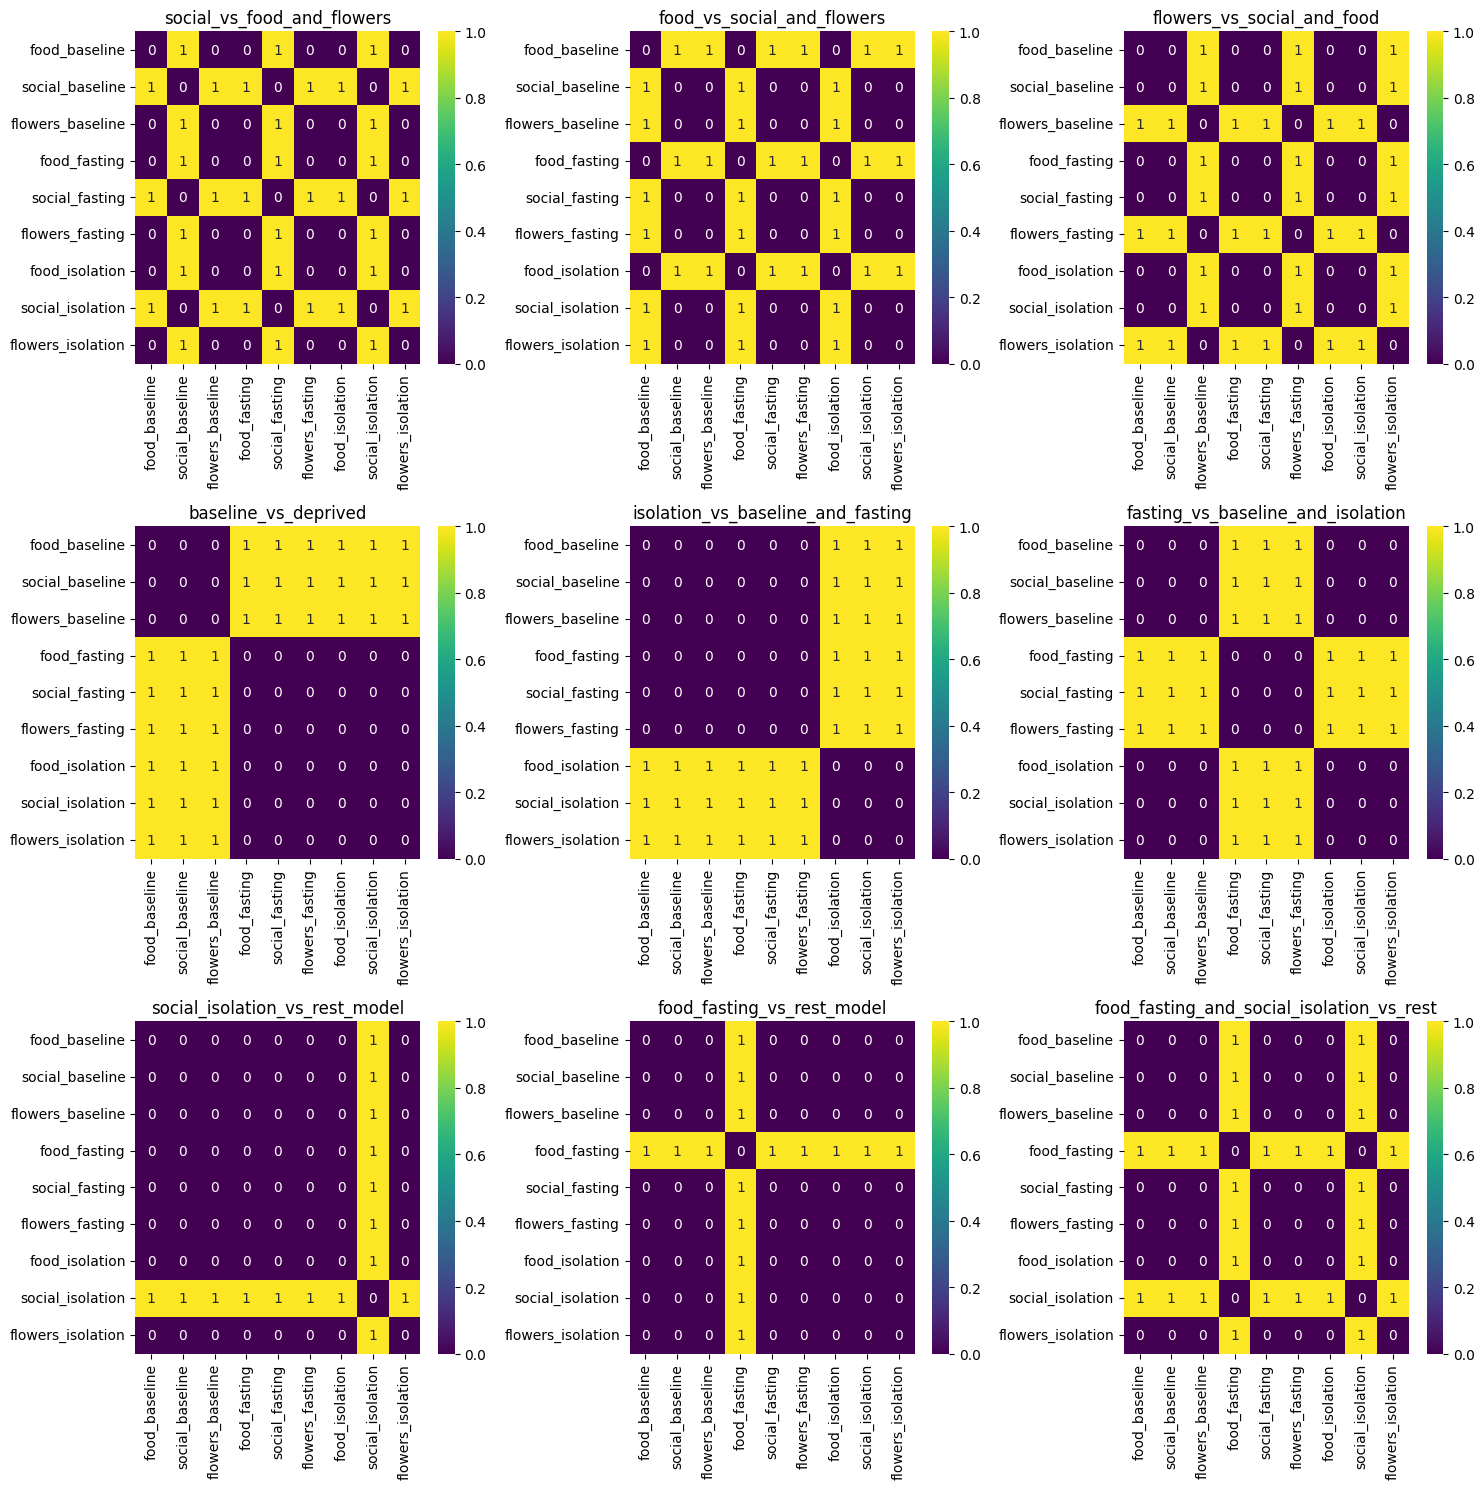

In [16]:
# plot all 9 RDMs on 3*3 grid

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for ax, (name, rdm) in zip(axes.flatten(), MODEL_RDMS.items()):
    sns.heatmap(rdm, annot=True, cmap="viridis", cbar=True, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [17]:
UPPER_TRIANGLE = np.triu_indices(
    len(CONDITIONS),
    k=1,
)

UPPER_TRIANGLE

(array([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 3,
        3, 3, 3, 3, 4, 4, 4, 4, 5, 5, 5, 6, 6, 7]),
 array([1, 2, 3, 4, 5, 6, 7, 8, 2, 3, 4, 5, 6, 7, 8, 3, 4, 5, 6, 7, 8, 4,
        5, 6, 7, 8, 5, 6, 7, 8, 6, 7, 8, 7, 8, 8]))

In [18]:
def vectorize_rdm(rdm):
    """
    Return the 36 unique off-diagonal entries of a 9 x 9 RDM.
    """
    ordered = rdm.loc[CONDITIONS, CONDITIONS]
    return ordered.to_numpy(dtype=float)[UPPER_TRIANGLE]

In [19]:
def compare_rdm_to_models(neural_rdm, model_rdms=MODEL_RDMS):
    neural_vector = vectorize_rdm(neural_rdm)

    return pd.Series(
        {
            name: stats.spearmanr(
                neural_vector,
                vectorize_rdm(model_rdm),
            )[0]
            for name, model_rdm in model_rdms.items()
        },
        name="spearman_rho",
    )

In [20]:
rdms["rdms"][list(rdms["subjects"]).index("sub-SAXSISO01"), list(rdms["rois"]).index("Pu.nii")]

array([[ 0.        ,  0.0501884 , -0.00102678,  0.05363569,  0.05038453,
         0.20948757,  0.32573402,  0.12635759,  0.15296879],
       [ 0.0501884 ,  0.        ,  0.01725196,  0.01909231,  0.00240232,
         0.05739799,  0.15682174,  0.02130025,  0.07626607],
       [-0.00102678,  0.01725196,  0.        ,  0.0202971 , -0.02474171,
         0.04477293,  0.24186863,  0.05753067,  0.101157  ],
       [ 0.05363569,  0.01909231,  0.0202971 ,  0.        ,  0.01250485,
         0.00589674,  0.04995241, -0.0402687 ,  0.02253497],
       [ 0.05038453,  0.00240232, -0.02474171,  0.01250485,  0.        ,
         0.0277144 ,  0.10195953, -0.05963177,  0.02111574],
       [ 0.20948757,  0.05739799,  0.04477293,  0.00589674,  0.0277144 ,
         0.        , -0.00731955, -0.1106239 , -0.0413376 ],
       [ 0.32573402,  0.15682174,  0.24186863,  0.04995241,  0.10195953,
        -0.00731955,  0.        ,  0.06033544,  0.01480729],
       [ 0.12635759,  0.02130025,  0.05753067, -0.0402687 , -0

In [21]:
excluded_rois.roi.to_list()

['Frontal Medial Cortex',
 'Inferior Frontal Gyrus, pars triangularis',
 'Lateral Occipital Cortex, superior division',
 'Middle Temporal Gyrus, temporooccipital part',
 'Subcallosal Cortex',
 'Superior Temporal Gyrus, anterior division']

In [22]:
# Calculate one rho per participant, ROI, and model.
model_vectors = {
    name: vectorize_rdm(model_rdm)
    for name, model_rdm in MODEL_RDMS.items()
}

score_rows = []

excluded_roi_list = excluded_rois.roi.to_list()
valid_df = df.query('included & roi not in @excluded_roi_list')


for atlas, subject, roi in valid_df[['atlas', 'subject', 'roi']].itertuples(index=False):
    neural_rdm = rdms["rdms"][list(rdms["subjects"]).index(subject), list(rdms["rois"]).index(f"{roi}.nii")]
    neural_vector = neural_rdm[UPPER_TRIANGLE]

    for model_name, model_vector in model_vectors.items():
        rho = stats.spearmanr(neural_vector, model_vector)[0]

        score_rows.append({
            "atlas": atlas,
            "subject": subject,
            "roi": roi,
            "model": model_name,
            "rho": rho,
        })

participant_scores = pd.DataFrame(score_rows)
participant_scores

,atlas,subject,roi,model,rho
0,cortical,sub-SAXSISO01,Insular Cortex,social_vs_food_and_flowers,0.299482
1,cortical,sub-SAXSISO01,Insular Cortex,food_vs_social_and_flowers,0.208568
2,cortical,sub-SAXSISO01,Insular Cortex,flowers_vs_social_and_food,-0.042783
3,cortical,sub-SAXSISO01,Insular Cortex,baseline_vs_deprived,0.310178
4,cortical,sub-SAXSISO01,Insular Cortex,isolation_vs_baseline_and_fasting,-0.262047
...,...,...,...,...,...
14287,midbrain,sub-SAXSISO42,SNc_VTA,isolation_vs_baseline_and_fasting,0.732662
14288,midbrain,sub-SAXSISO42,SNc_VTA,fasting_vs_baseline_and_isolation,-0.090914
14289,midbrain,sub-SAXSISO42,SNc_VTA,social_isolation_vs_rest_model,0.334453
14290,midbrain,sub-SAXSISO42,SNc_VTA,food_fasting_vs_rest_model,0.334453


In [24]:
behavioral_df = pd.read_csv('probing_rsa_fasting_social_isolation/dataframes/SISO_behavioral_data.csv')
behavioral_df['subject'] = behavioral_df['ID'].apply(lambda x: 'sub-' + x.replace('_', ''))
behavioral_df.head()

,ID,Age,Gender,Monthly_Interactions,BMI,Close_Relationships,Loneliness_Score,rating_social_baseline,rating_food_baseline,rating_social_fasted,...,Isolation_Lonely2,Isolation_Lonely3,Isolation_Lonely4,Isolation_Lonely5,Isolation_Lonely6,ZMonthly_Interactions,ZClose_Relationships,ZMean_SocialNetwork,Dominance_Score,subject
0,SAX_SISO_01,20,female,40,23.17,17,42,6.555556,7.388889,7.333333,...,44,60,40,41,47,-0.287937,0.929948,0.321006,23,sub-SAXSISO01
1,SAX_SISO_02,19,female,51,21.96,15,36,7.444444,7.388889,4.611111,...,40,50,50,45,45,0.059165,0.538391,0.298778,22,sub-SAXSISO02
2,SAX_SISO_03,30,female,148,18.79,20,30,6.611111,6.055556,6.166667,...,20,20,35,56,57,3.119974,1.517284,2.318629,22,sub-SAXSISO03
3,SAX_SISO_04,27,female,28,23.44,7,30,7.888889,8.833333,7.000000,...,41,32,40,43,47,-0.666594,-1.027837,-0.847216,21,sub-SAXSISO04
4,SAX_SISO_05,19,female,83,19.69,20,34,6.055556,6.333333,5.583333,...,35,40,40,40,50,1.068917,1.517284,1.293100,24,sub-SAXSISO05


In [25]:
behavioral_df = pd.read_csv('probing_rsa_fasting_social_isolation/dataframes/SISO_behavioral_data.csv')
behavioral_df['subject'] = behavioral_df['ID'].apply(lambda x: 'sub-' + x.replace('_', ''))


participant_scores['Loneliness_Score'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Loneliness_Score'])
participant_scores['Close_Relationships'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Close_Relationships'])
participant_scores['Monthly_Interactions'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Monthly_Interactions'])
participant_scores['Isolation_Lonely6'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Isolation_Lonely6'])

participant_scores.head()

,atlas,subject,roi,model,rho,Loneliness_Score,Close_Relationships,Monthly_Interactions,Isolation_Lonely6
0,cortical,sub-SAXSISO01,Insular Cortex,social_vs_food_and_flowers,0.299482,42,17,40,47
1,cortical,sub-SAXSISO01,Insular Cortex,food_vs_social_and_flowers,0.208568,42,17,40,47
2,cortical,sub-SAXSISO01,Insular Cortex,flowers_vs_social_and_food,-0.042783,42,17,40,47
3,cortical,sub-SAXSISO01,Insular Cortex,baseline_vs_deprived,0.310178,42,17,40,47
4,cortical,sub-SAXSISO01,Insular Cortex,isolation_vs_baseline_and_fasting,-0.262047,42,17,40,47


In [94]:
summary_rows = []

rng = np.random.default_rng(42)
n_bootstrap = 10_000

for (atlas, roi, model), group in participant_scores.groupby(
    ["atlas", "roi", "model"]
):
    rhos = group["rho"].to_numpy(dtype=float)
    rhos = rhos[np.isfinite(rhos)]
    n = len(rhos)

    if n >= 2:
        # Arithmetic mean of participants' original Spearman correlations.
        mean_rho = np.mean(rhos)

        # Resample participants' scores, not individual RDM entries.
        bootstrap_result = stats.bootstrap(
            (rhos,),
            statistic=np.mean,
            n_resamples=n_bootstrap,
            confidence_level=0.95,
            method="percentile",
            random_state=rng,
        )

        ci_lower = bootstrap_result.confidence_interval.low
        ci_upper = bootstrap_result.confidence_interval.high

        # Two-sided test of whether the population mean raw rho is zero.
        test = stats.ttest_1samp(rhos, popmean=0)
        p_value = test.pvalue
    else:
        mean_rho = ci_lower = ci_upper = p_value = np.nan

    summary_rows.append({
        "atlas": atlas,
        "roi": roi,
        "model": model,
        "n_participants": n,
        "mean_rho": mean_rho,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "p_value": p_value,
    })

model_summary = pd.DataFrame(summary_rows)

In [95]:
model_summary

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value
0,cortical,Angular Gyrus,baseline_vs_deprived,32,-0.048800,-0.113146,0.016879,0.151333
1,cortical,Angular Gyrus,fasting_vs_baseline_and_isolation,32,-0.027909,-0.100273,0.046965,0.467112
2,cortical,Angular Gyrus,flowers_vs_social_and_food,32,0.014038,-0.029413,0.062508,0.564750
3,cortical,Angular Gyrus,food_fasting_and_social_isolation_vs_rest,32,0.087418,0.031710,0.145182,0.006048
4,cortical,Angular Gyrus,food_fasting_vs_rest_model,32,-0.064921,-0.123812,-0.002206,0.048265
...,...,...,...,...,...,...,...,...
463,subcortical,Thalamus,food_fasting_vs_rest_model,32,-0.054469,-0.136073,0.034370,0.219328
464,subcortical,Thalamus,food_vs_social_and_flowers,32,-0.028076,-0.085566,0.034933,0.375494
465,subcortical,Thalamus,isolation_vs_baseline_and_fasting,32,0.043117,-0.044789,0.137708,0.371904
466,subcortical,Thalamus,social_isolation_vs_rest_model,32,0.167226,0.074368,0.260889,0.001660


In [96]:
model_summary[ "p_fdr"] = multipletests(
            model_summary["p_value"],
            method="fdr_bh")[1]

model_summary

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
0,cortical,Angular Gyrus,baseline_vs_deprived,32,-0.048800,-0.113146,0.016879,0.151333,0.329413
1,cortical,Angular Gyrus,fasting_vs_baseline_and_isolation,32,-0.027909,-0.100273,0.046965,0.467112,0.689617
2,cortical,Angular Gyrus,flowers_vs_social_and_food,32,0.014038,-0.029413,0.062508,0.564750,0.767214
3,cortical,Angular Gyrus,food_fasting_and_social_isolation_vs_rest,32,0.087418,0.031710,0.145182,0.006048,0.032537
4,cortical,Angular Gyrus,food_fasting_vs_rest_model,32,-0.064921,-0.123812,-0.002206,0.048265,0.149639
...,...,...,...,...,...,...,...,...,...
463,subcortical,Thalamus,food_fasting_vs_rest_model,32,-0.054469,-0.136073,0.034370,0.219328,0.415569
464,subcortical,Thalamus,food_vs_social_and_flowers,32,-0.028076,-0.085566,0.034933,0.375494,0.581892
465,subcortical,Thalamus,isolation_vs_baseline_and_fasting,32,0.043117,-0.044789,0.137708,0.371904,0.581892
466,subcortical,Thalamus,social_isolation_vs_rest_model,32,0.167226,0.074368,0.260889,0.001660,0.011099


In [97]:
model_summary.query('p_fdr < 0.05').sort_values("p_fdr")

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
260,cortical,Temporal Occipital Fusiform Cortex,social_vs_food_and_flowers,32,0.714279,0.662467,0.762577,5.950069e-23,2.784632e-20
8,cortical,Angular Gyrus,social_vs_food_and_flowers,32,0.579244,0.511389,0.644426,4.691879e-17,1.097900e-14
251,cortical,"Supramarginal Gyrus, posterior division",social_vs_food_and_flowers,32,0.575568,0.498023,0.649268,2.031592e-15,2.376963e-13
422,subcortical,Cerebral White Matter,social_vs_food_and_flowers,32,0.564705,0.490001,0.638911,1.822089e-15,2.376963e-13
143,cortical,"Parahippocampal Gyrus, posterior division",social_vs_food_and_flowers,30,0.519103,0.437275,0.596647,3.061228e-13,2.865309e-11
...,...,...,...,...,...,...,...,...,...
299,midbrain,HTH,flowers_vs_social_and_food,30,0.101788,0.034757,0.173807,7.404800e-03,3.687449e-02
237,cortical,"Supramarginal Gyrus, anterior division",food_fasting_and_social_isolation_vs_rest,22,0.118926,0.041886,0.198459,8.621383e-03,4.247165e-02
176,cortical,Postcentral Gyrus,food_vs_social_and_flowers,30,0.085745,0.027983,0.145646,8.781314e-03,4.280890e-02
462,subcortical,Thalamus,food_fasting_and_social_isolation_vs_rest,32,0.109187,0.035649,0.185129,9.406004e-03,4.538155e-02


food, baseline: food_baseline
food, fasting: food_fasting
social, baseline: social_baseline
social, isolation: social_isolation
flowers, baseline: flowers_baseline
flowers, fasting: flowers_fasting
Skipping Frontal Pole.nii: insufficient complete pairs.


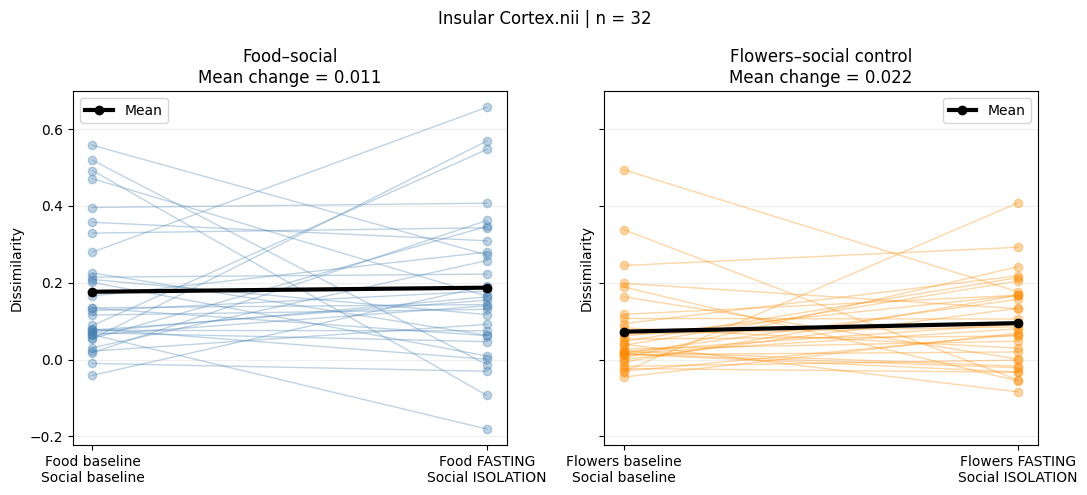

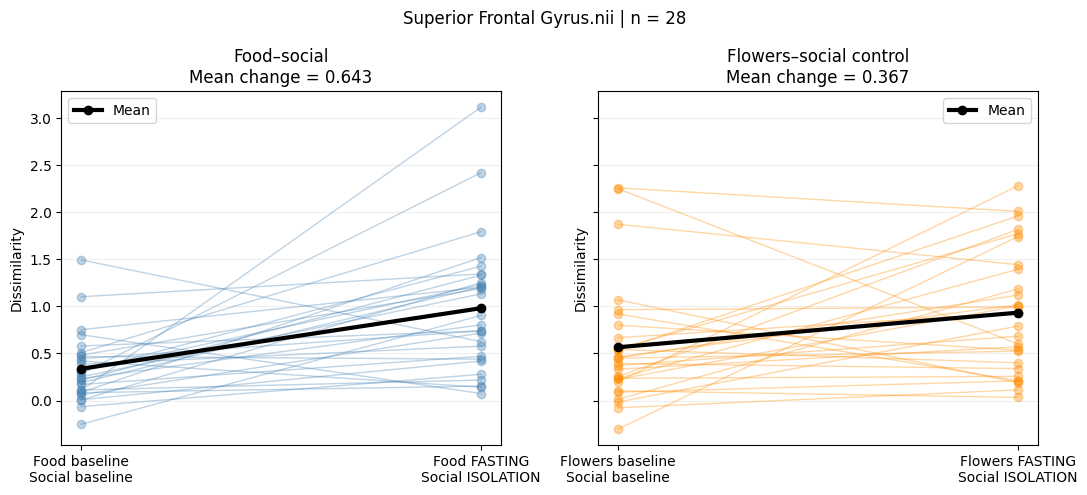

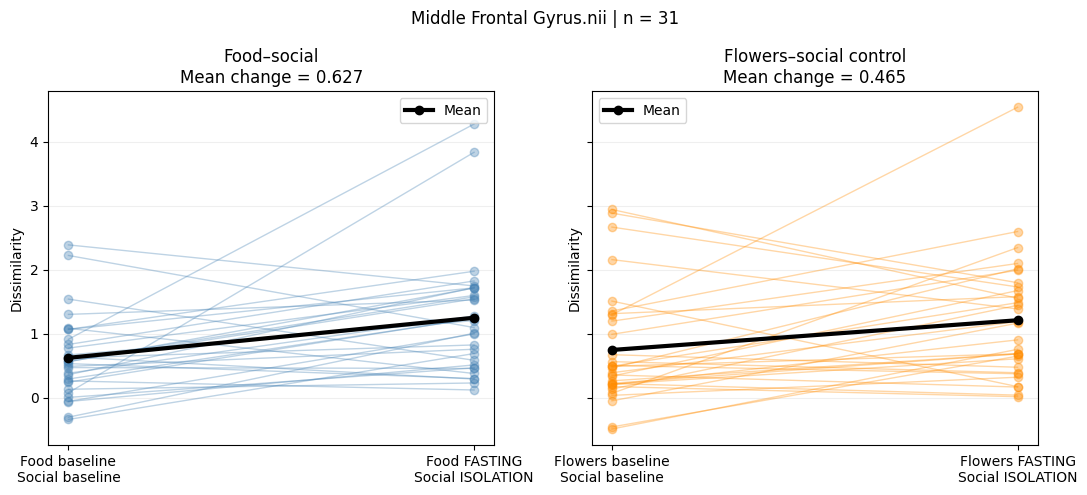

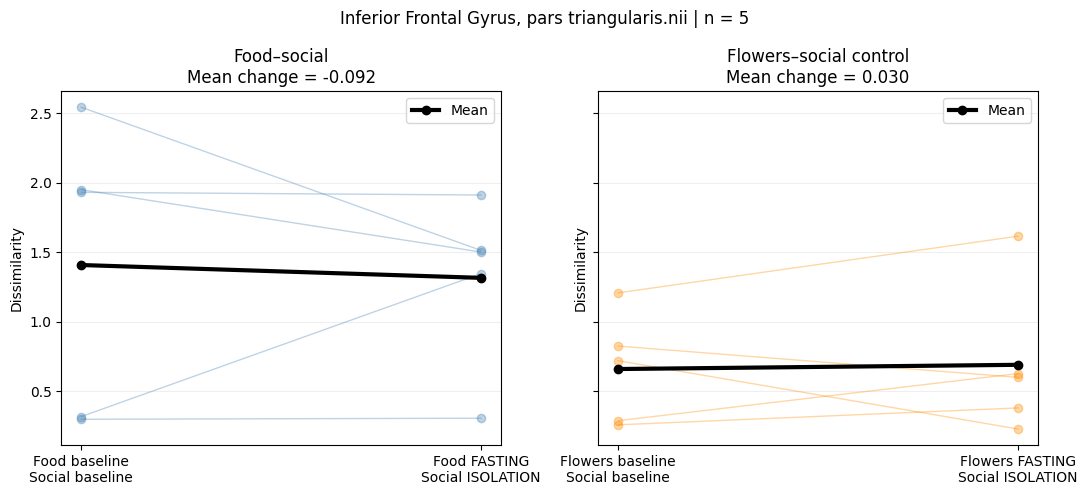

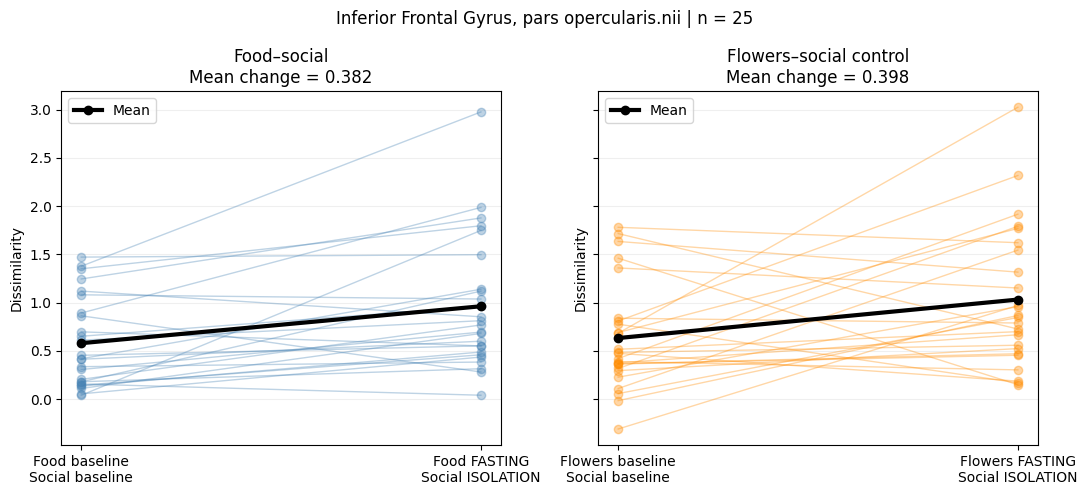

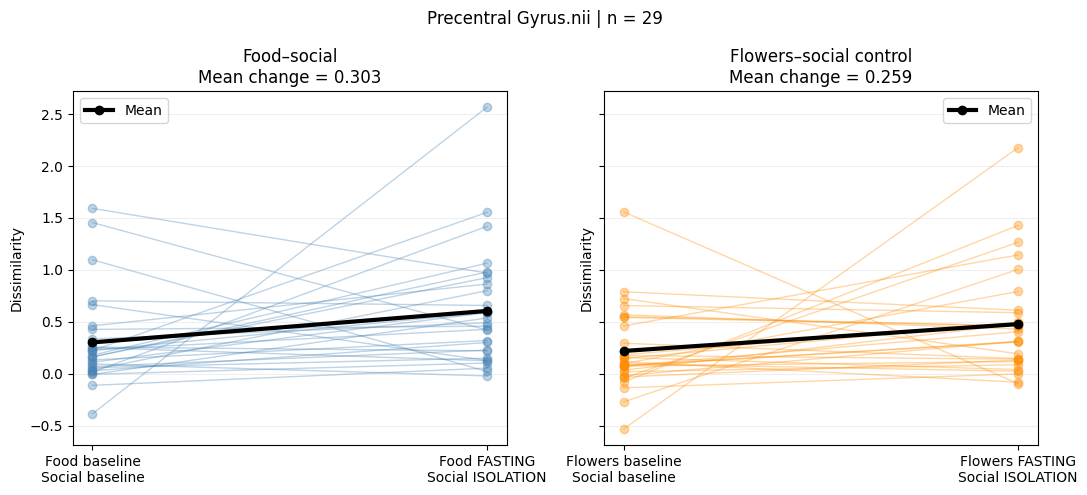

Skipping Temporal Pole.nii: insufficient complete pairs.


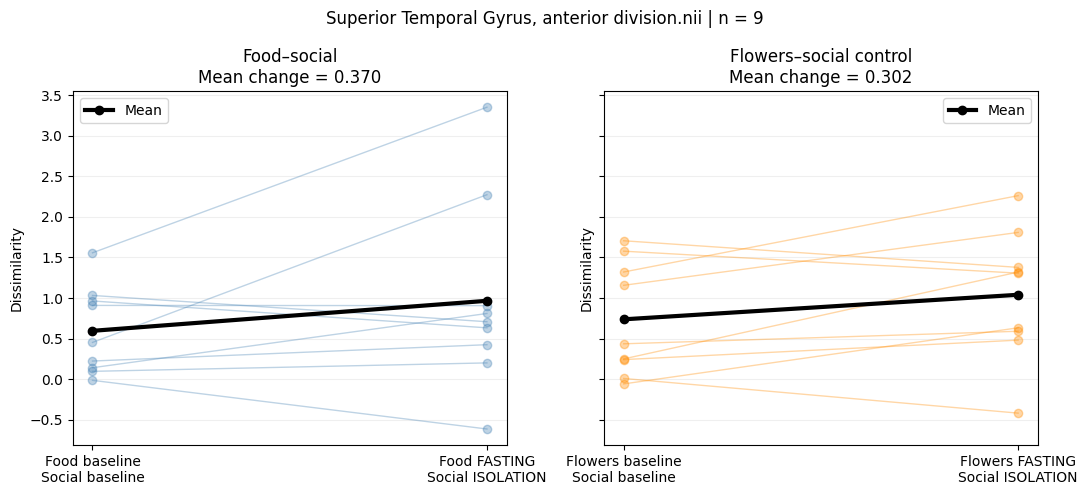

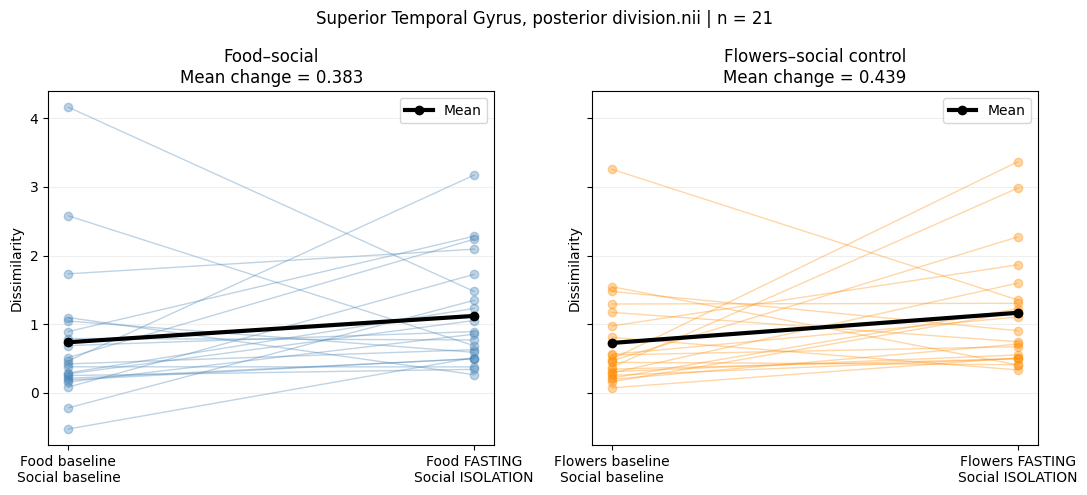

Skipping Middle Temporal Gyrus, anterior division.nii: insufficient complete pairs.
Skipping Middle Temporal Gyrus, posterior division.nii: insufficient complete pairs.
Skipping Middle Temporal Gyrus, temporooccipital part.nii: insufficient complete pairs.
Skipping Inferior Temporal Gyrus, anterior division.nii: insufficient complete pairs.
Skipping Inferior Temporal Gyrus, posterior division.nii: insufficient complete pairs.
Skipping Inferior Temporal Gyrus, temporooccipital part.nii: insufficient complete pairs.


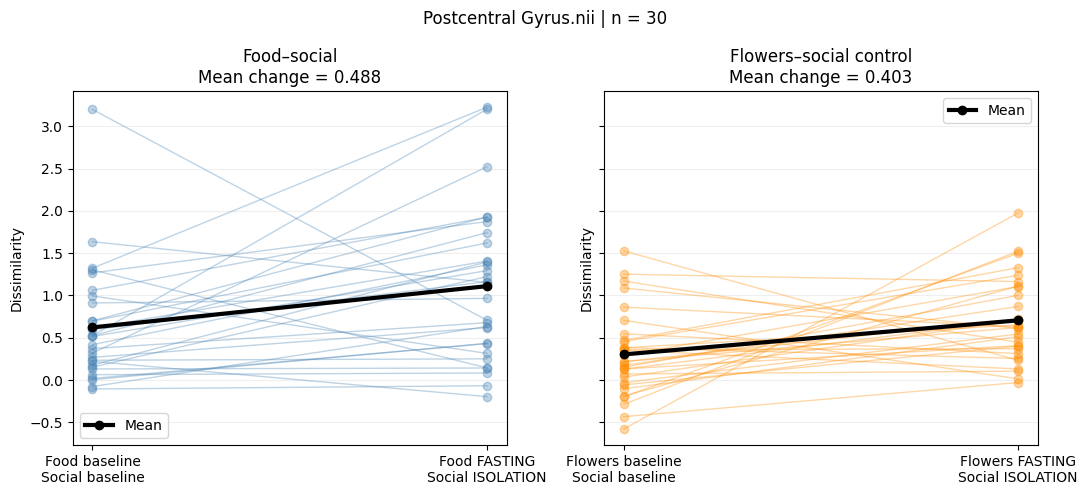

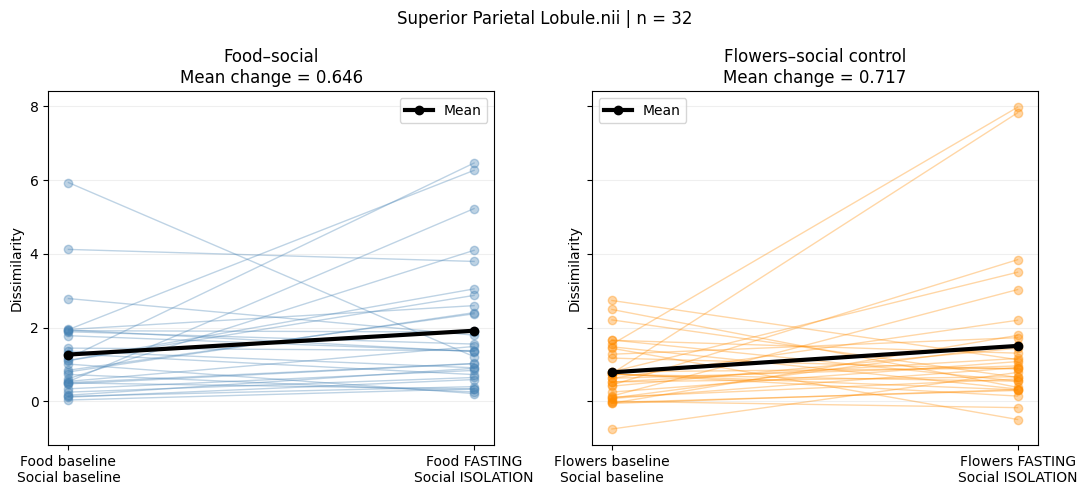

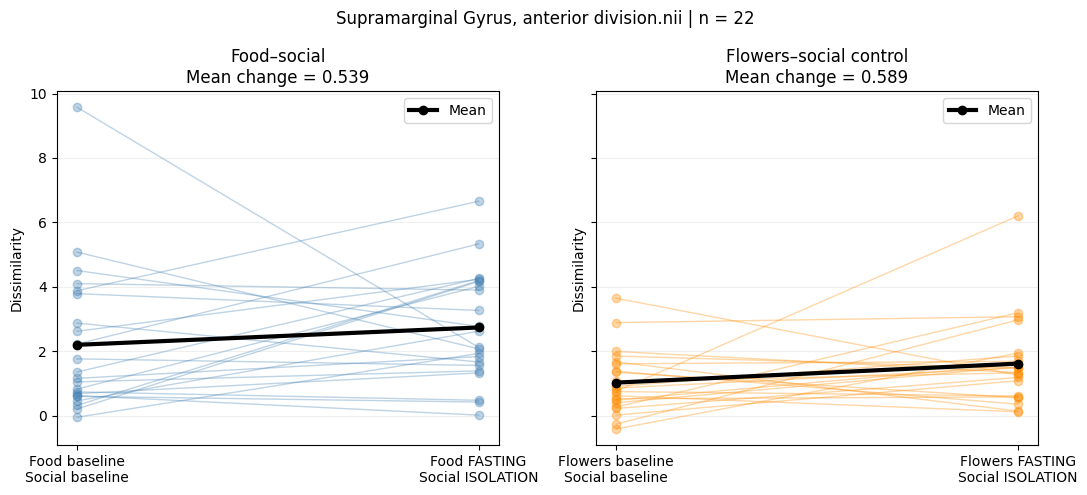

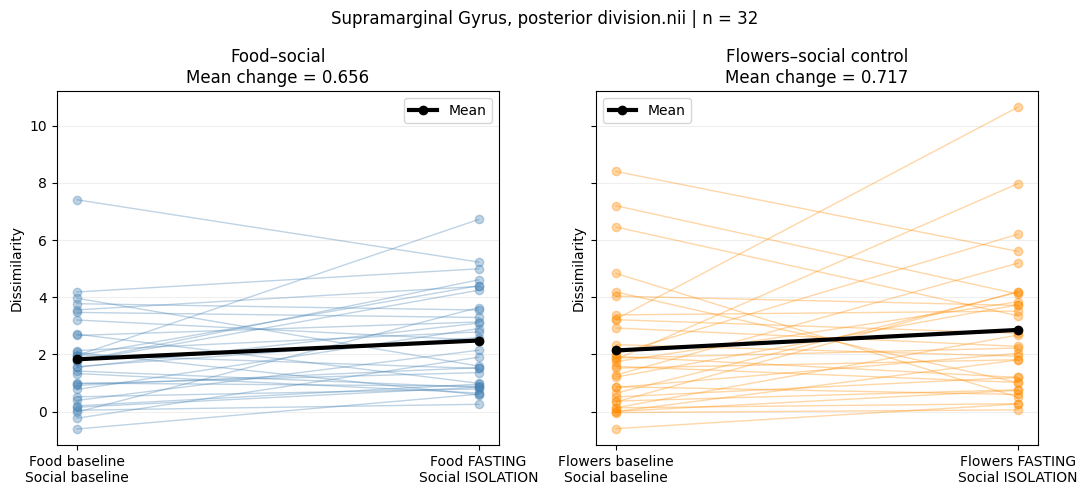

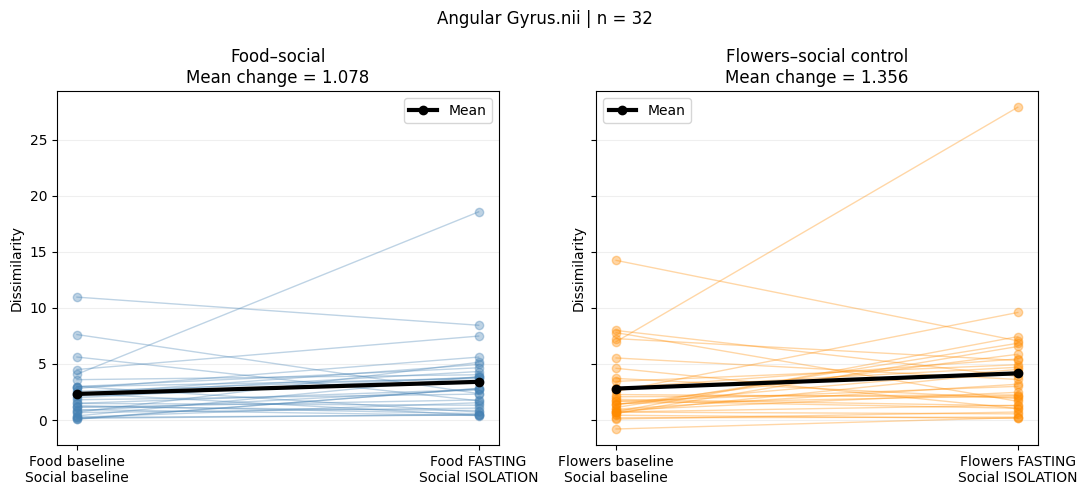

Skipping Lateral Occipital Cortex, superior division.nii: insufficient complete pairs.
Skipping Lateral Occipital Cortex, inferior division.nii: insufficient complete pairs.


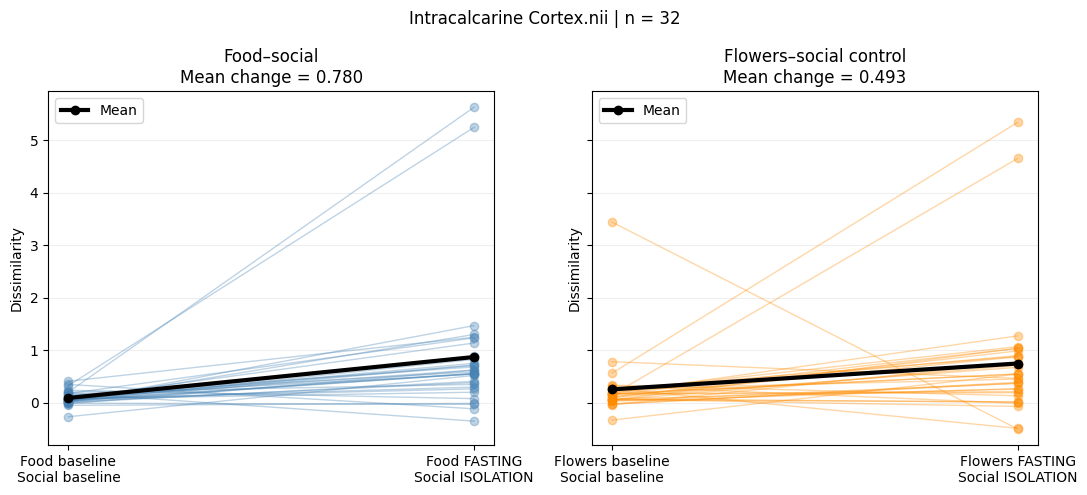

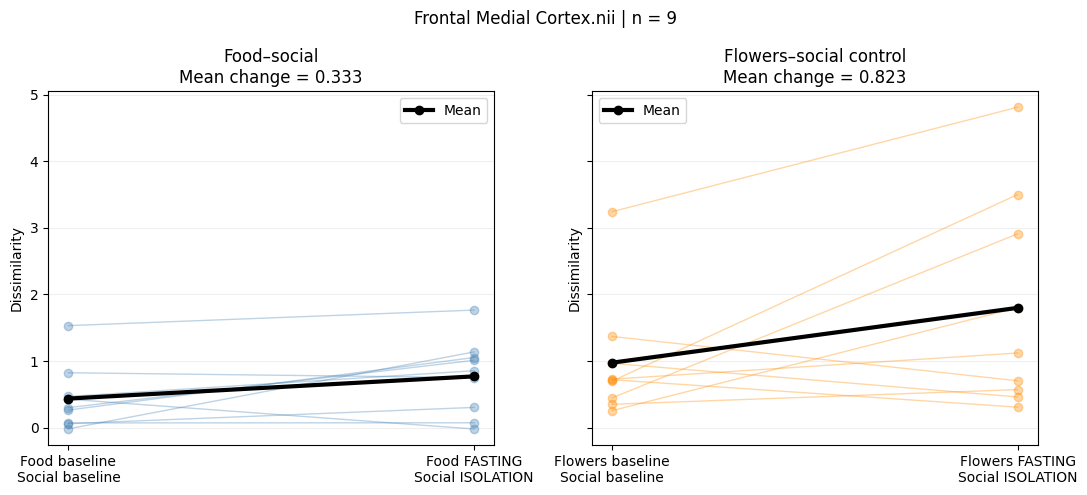

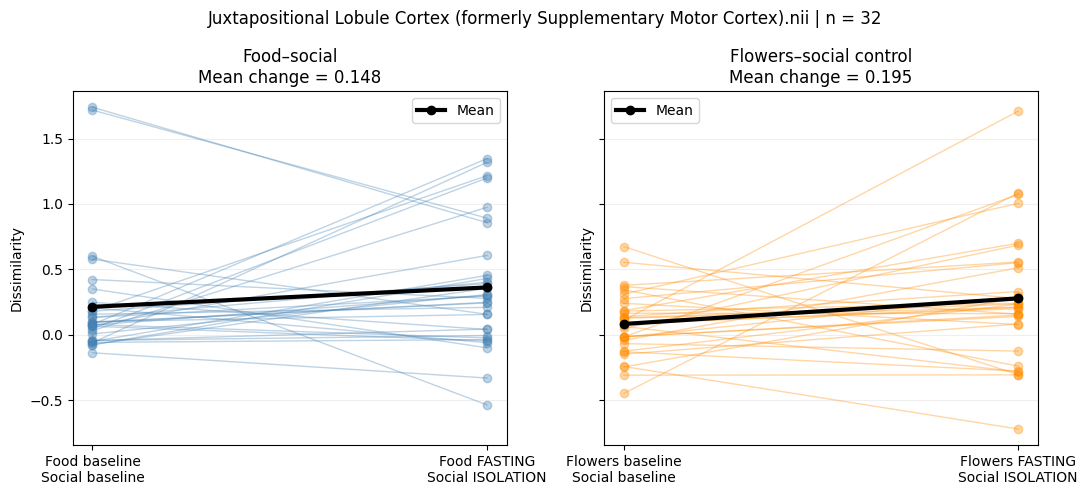

Skipping Subcallosal Cortex.nii: insufficient complete pairs.


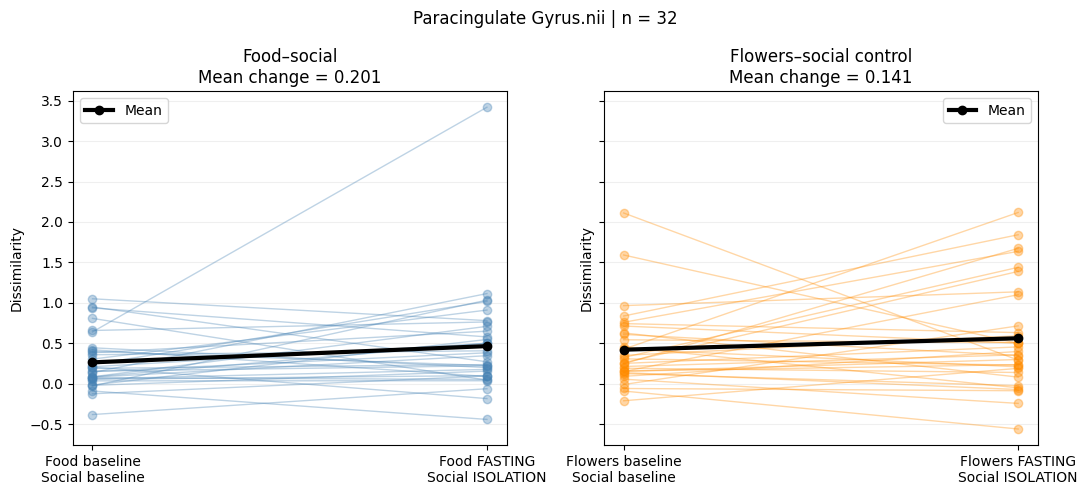

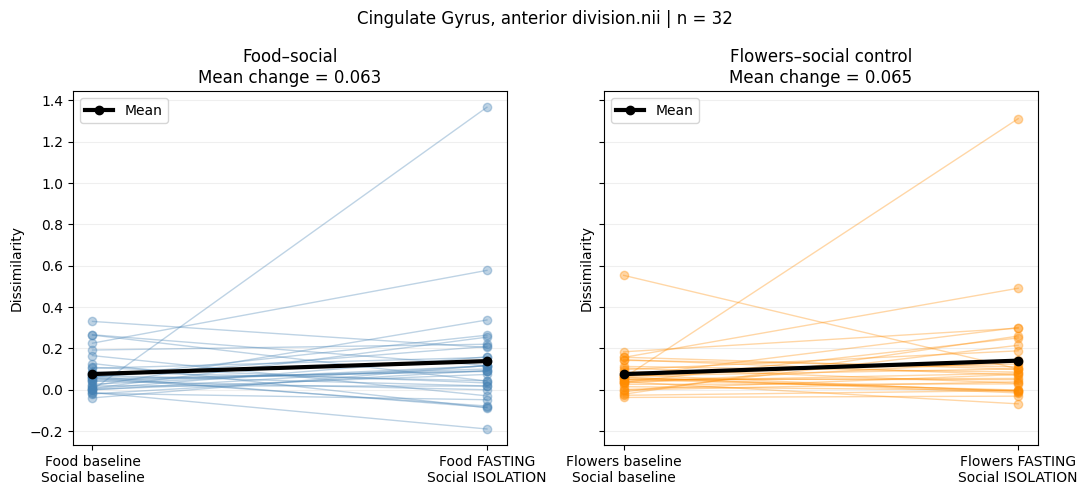

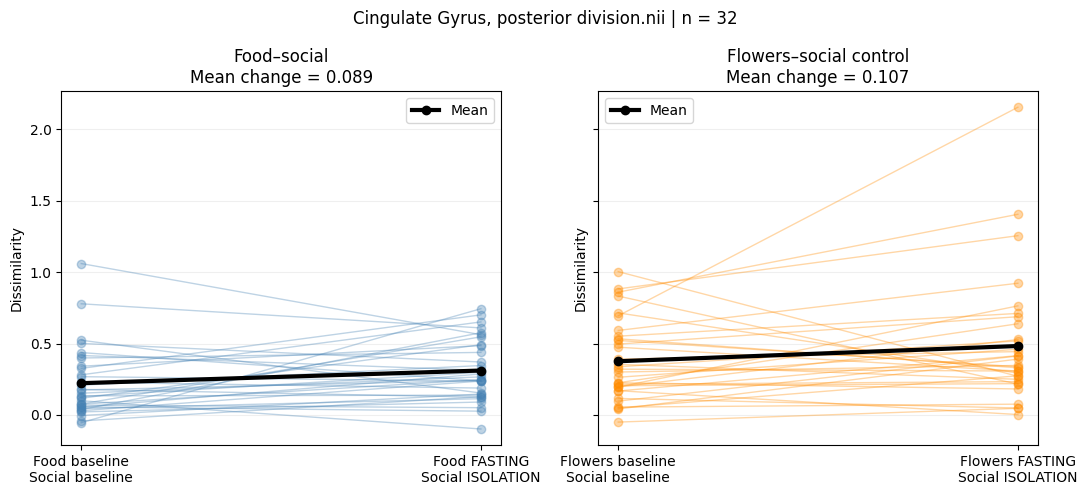

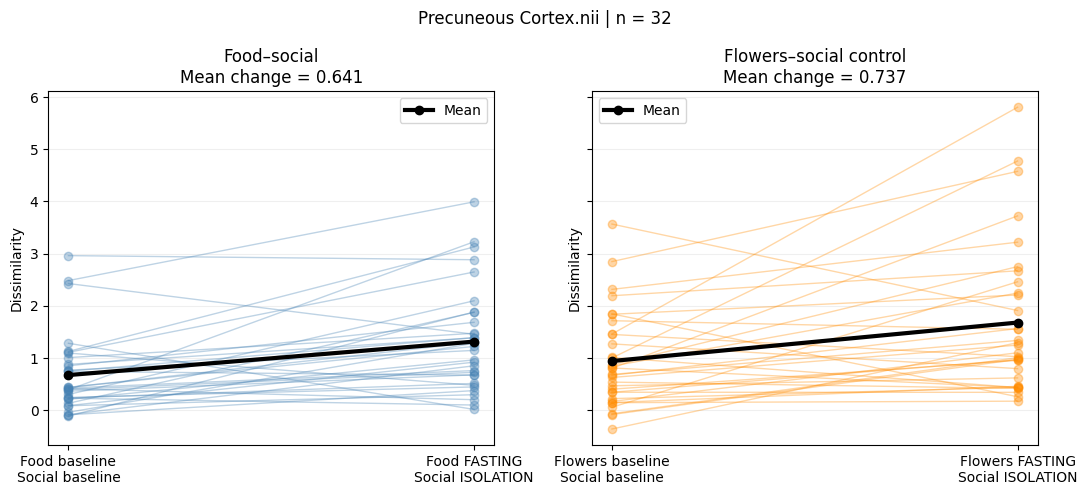

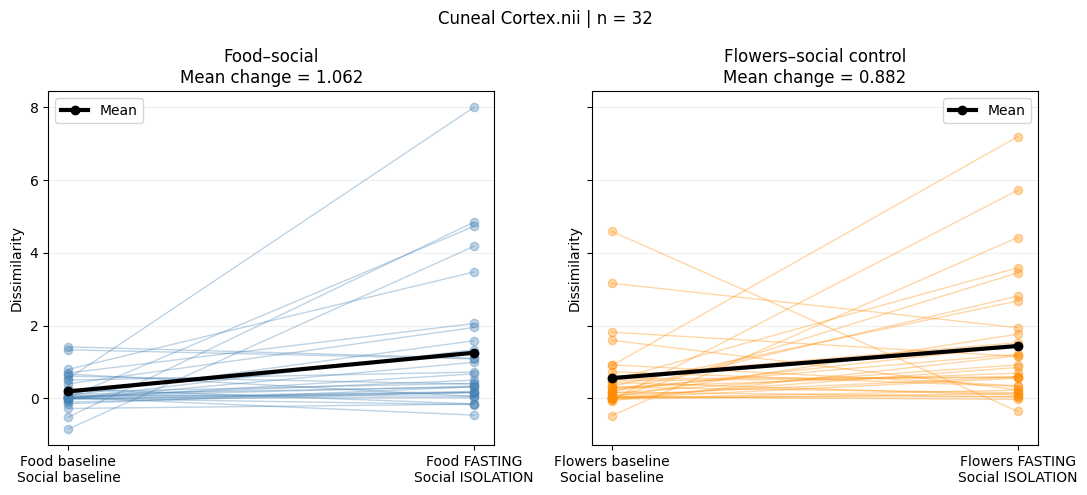

Skipping Frontal Orbital Cortex.nii: insufficient complete pairs.
Skipping Parahippocampal Gyrus, anterior division.nii: insufficient complete pairs.


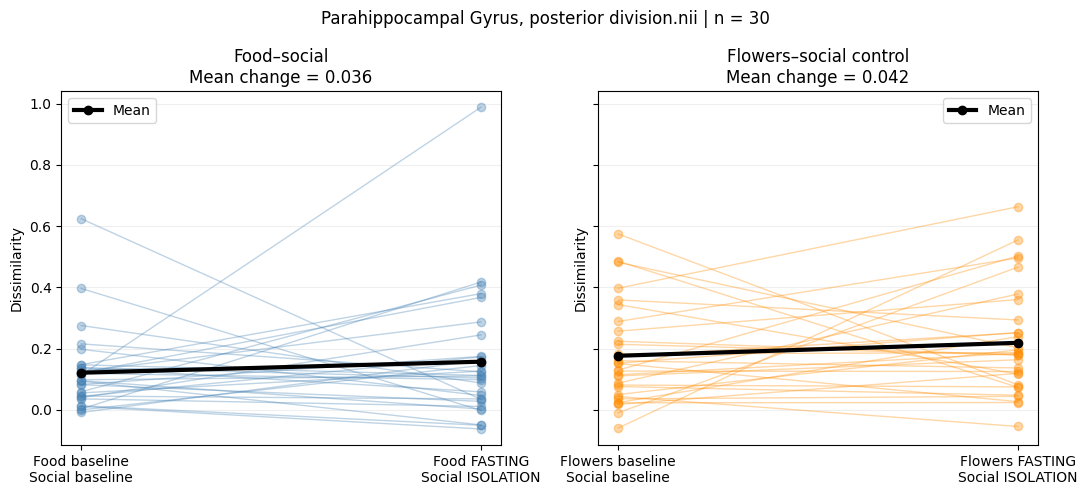

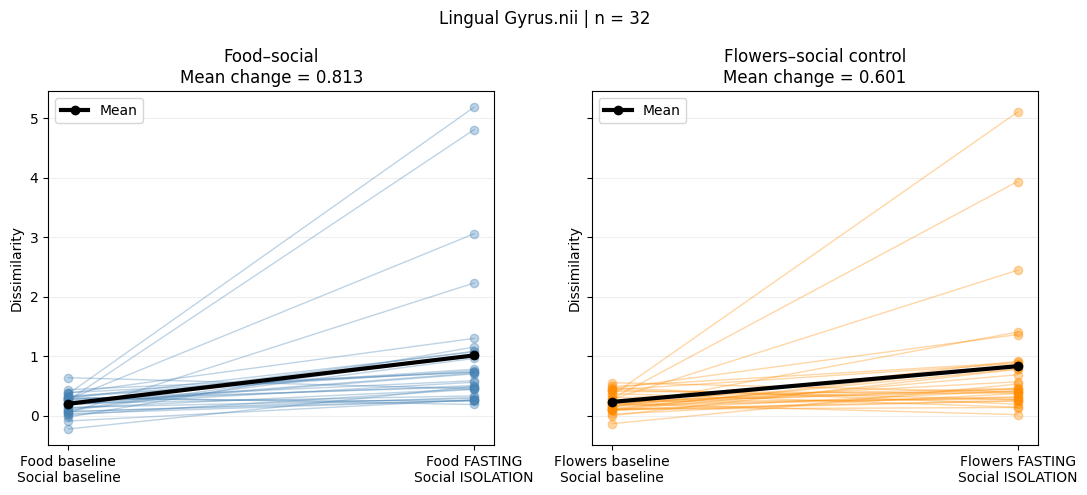

Skipping Temporal Fusiform Cortex, anterior division.nii: insufficient complete pairs.
Skipping Temporal Fusiform Cortex, posterior division.nii: insufficient complete pairs.


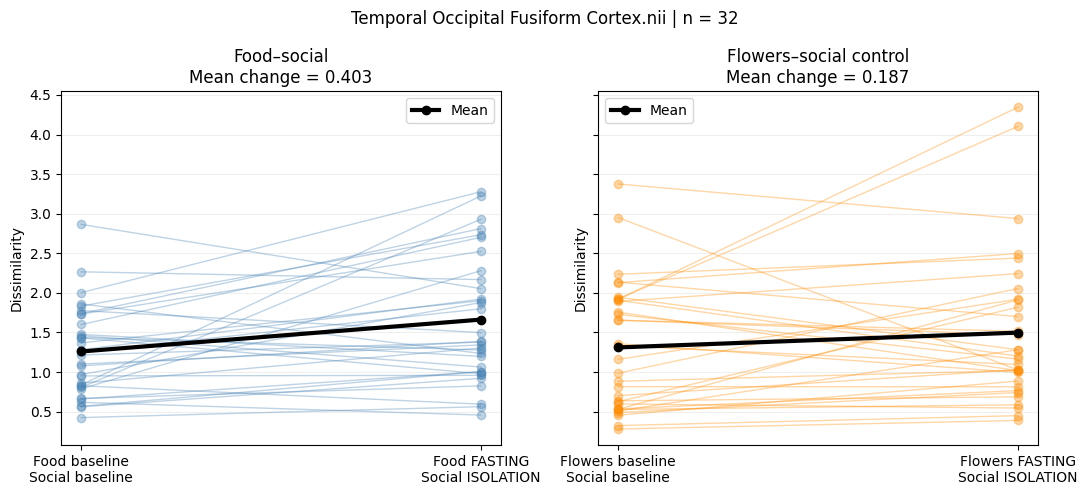

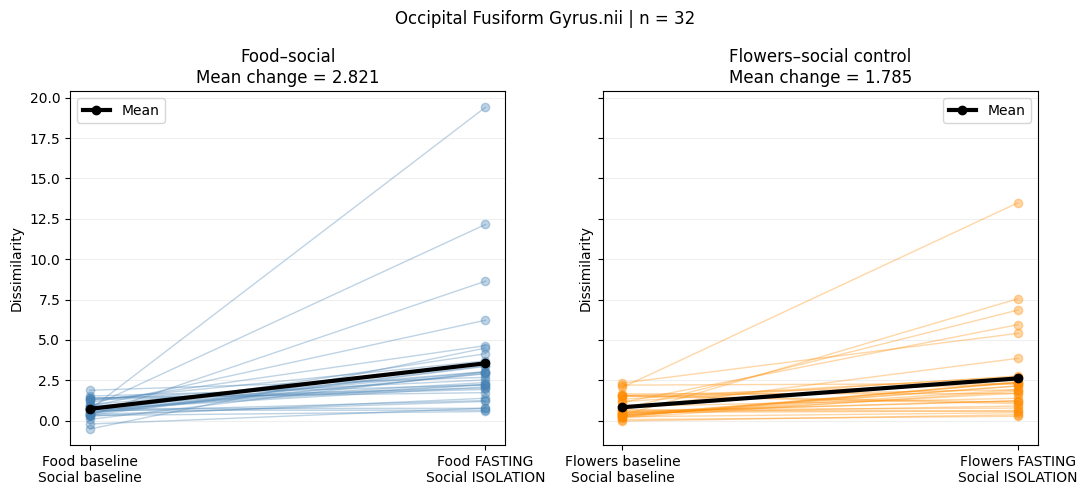

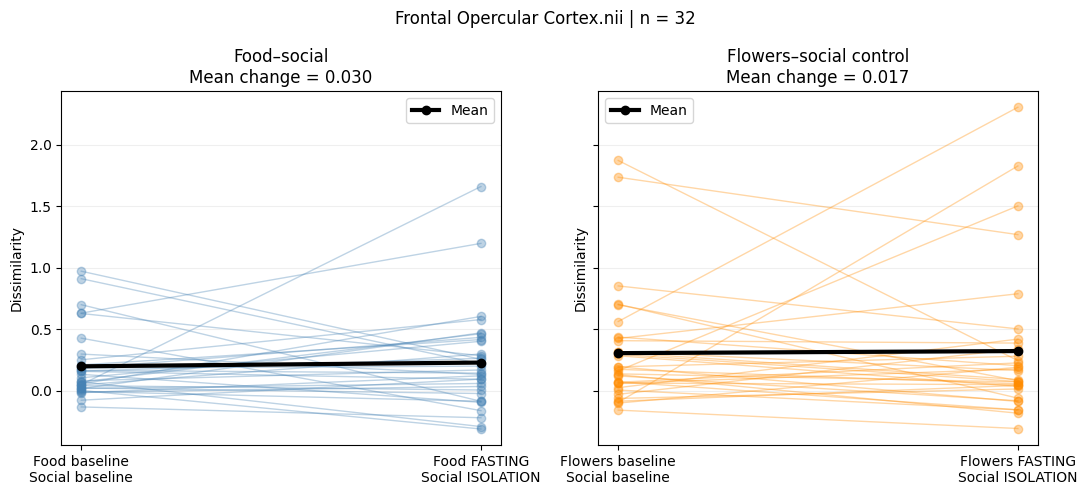

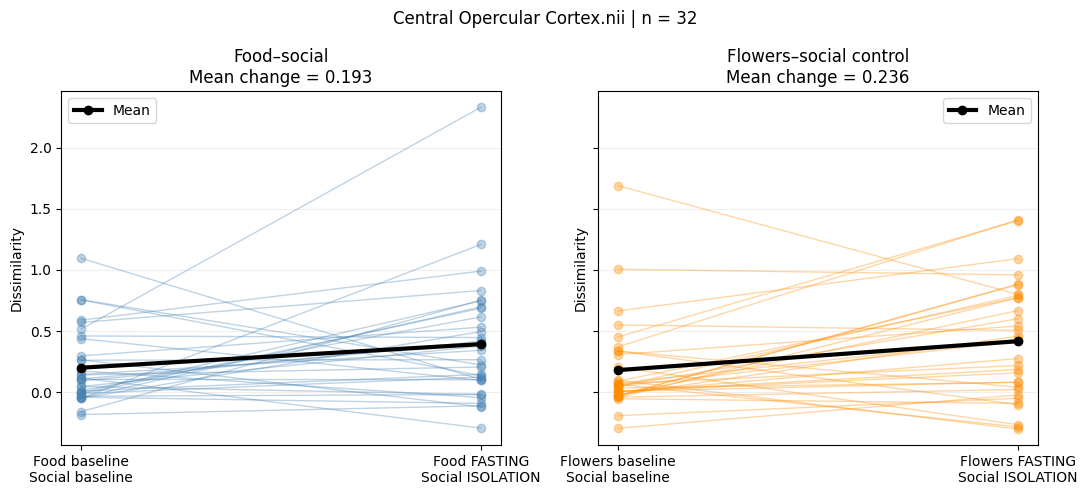

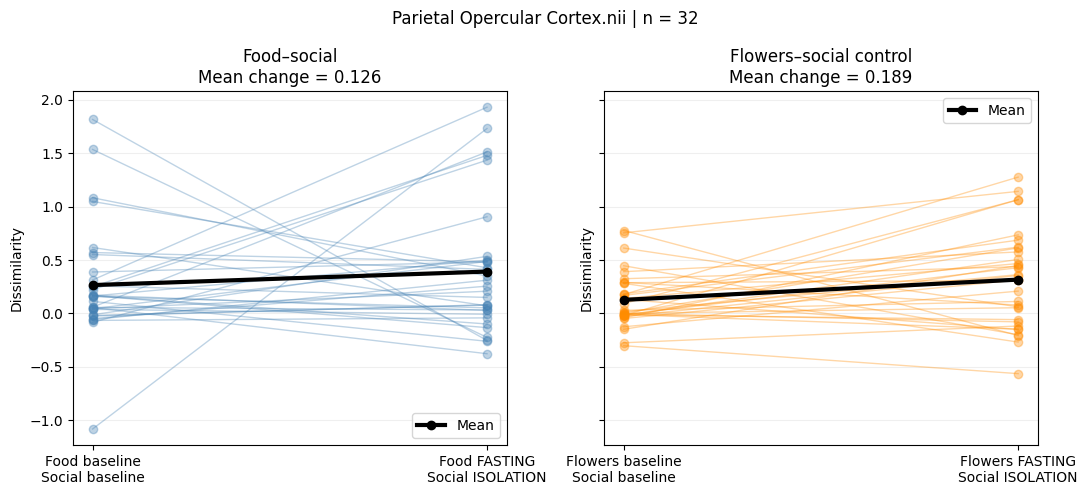

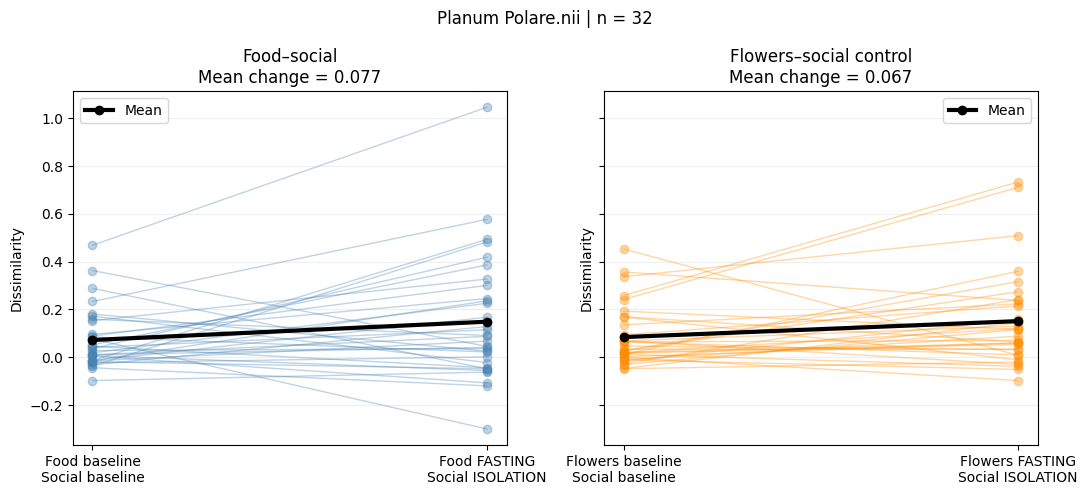

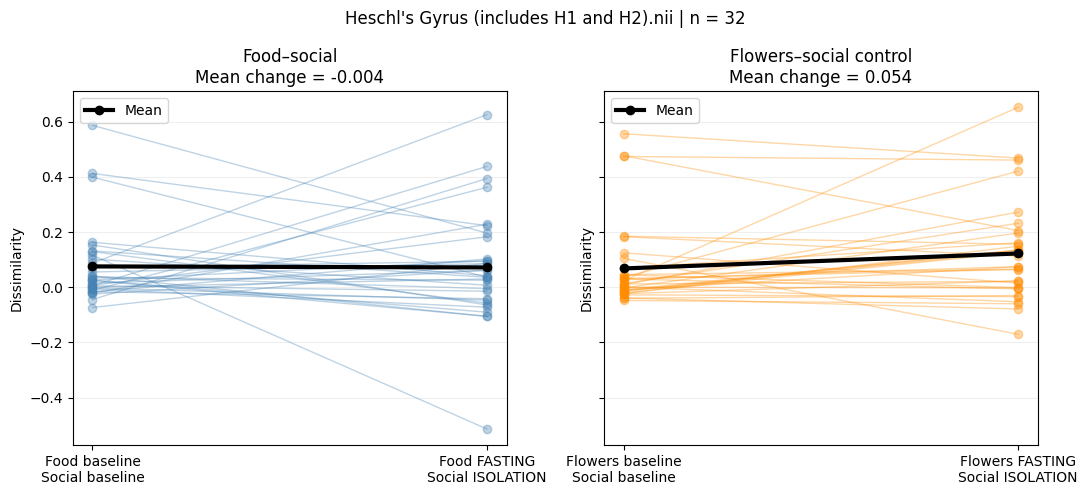

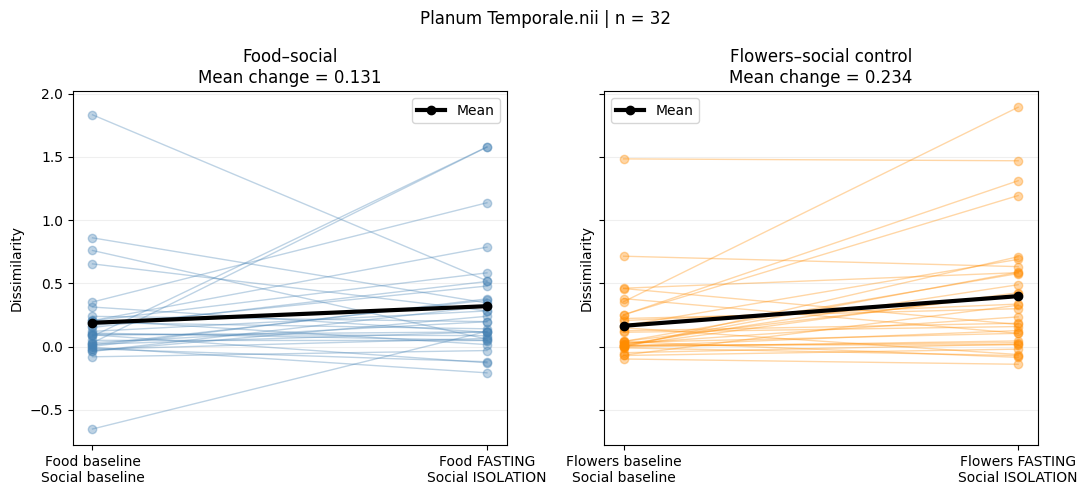

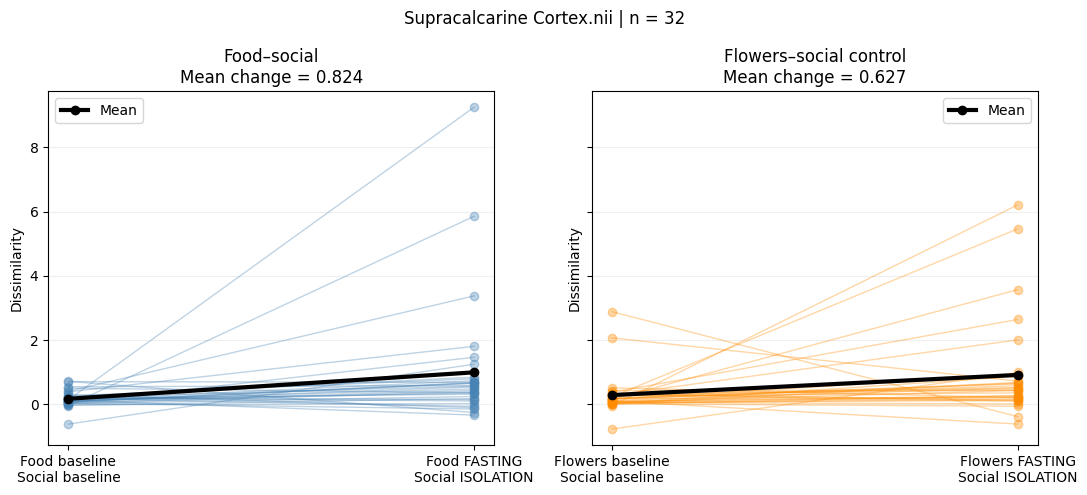

Skipping Occipital Pole.nii: insufficient complete pairs.


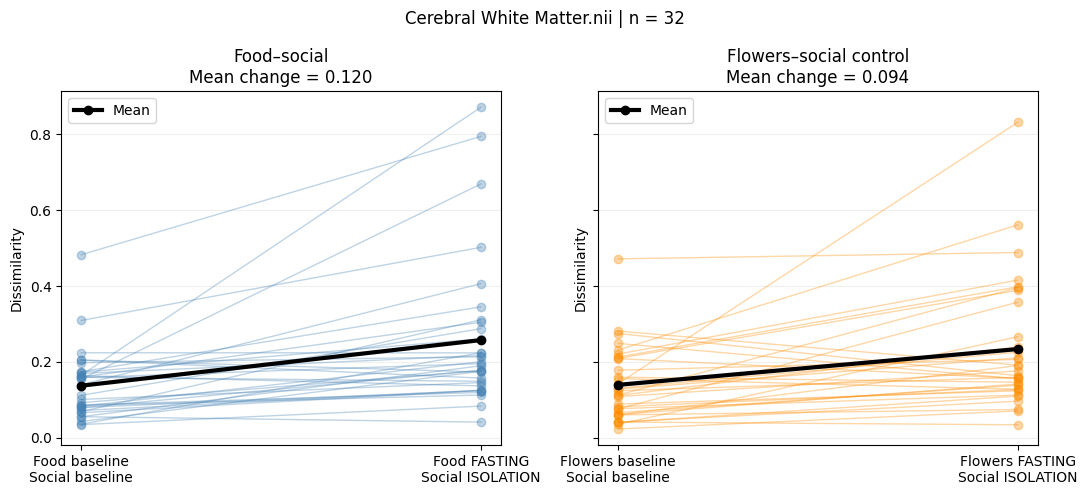

Skipping Cerebral Cortex.nii: insufficient complete pairs.


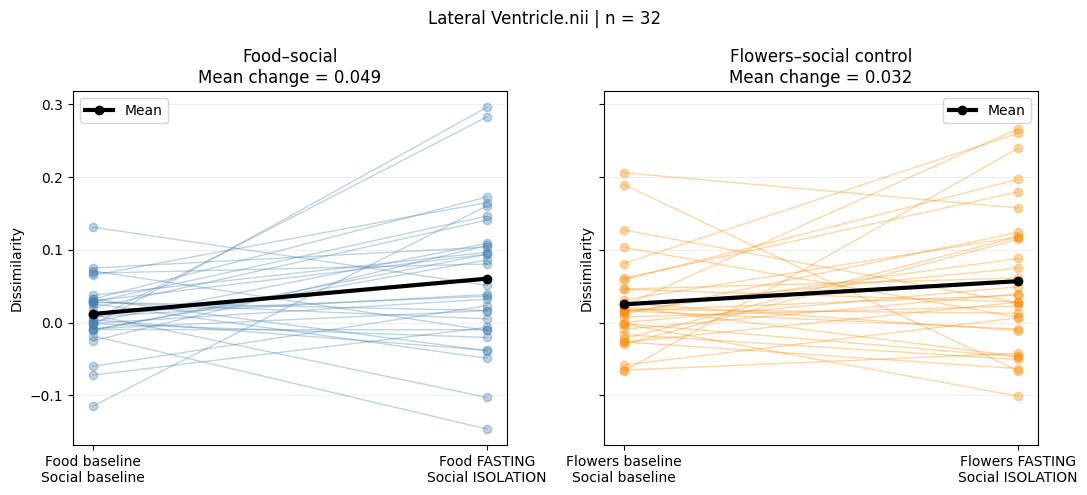

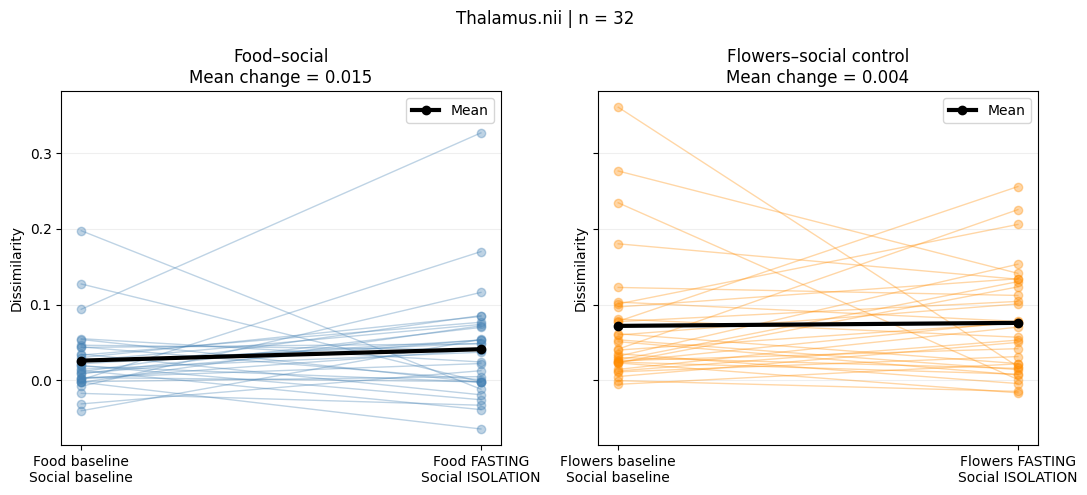

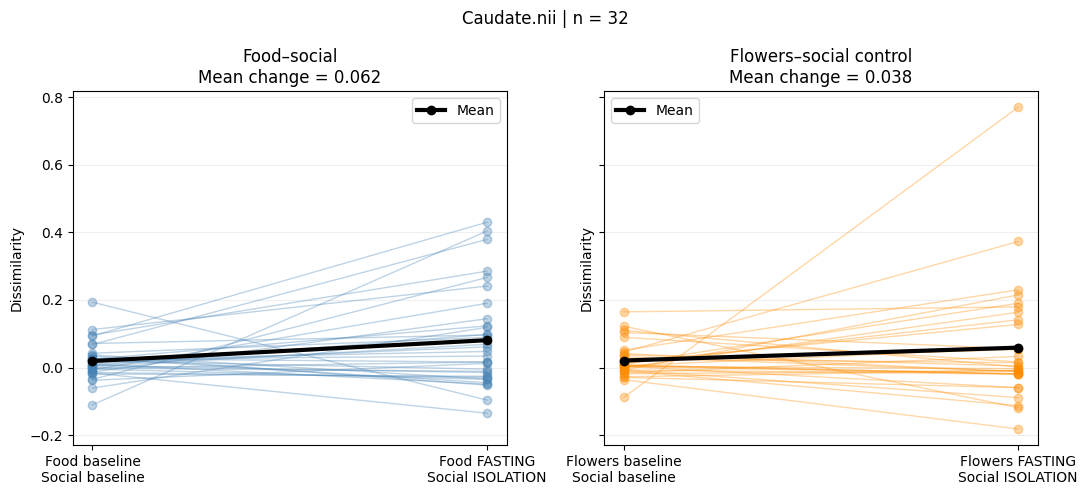

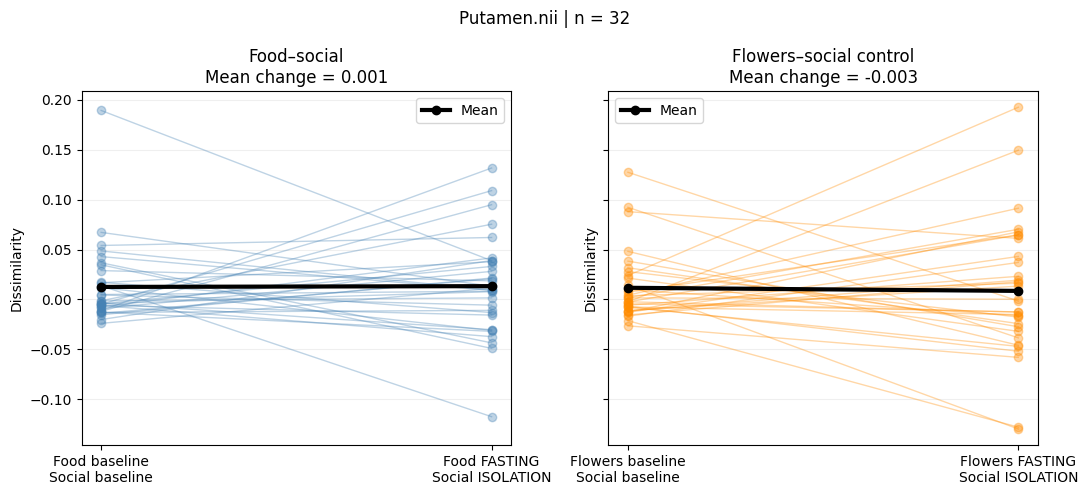

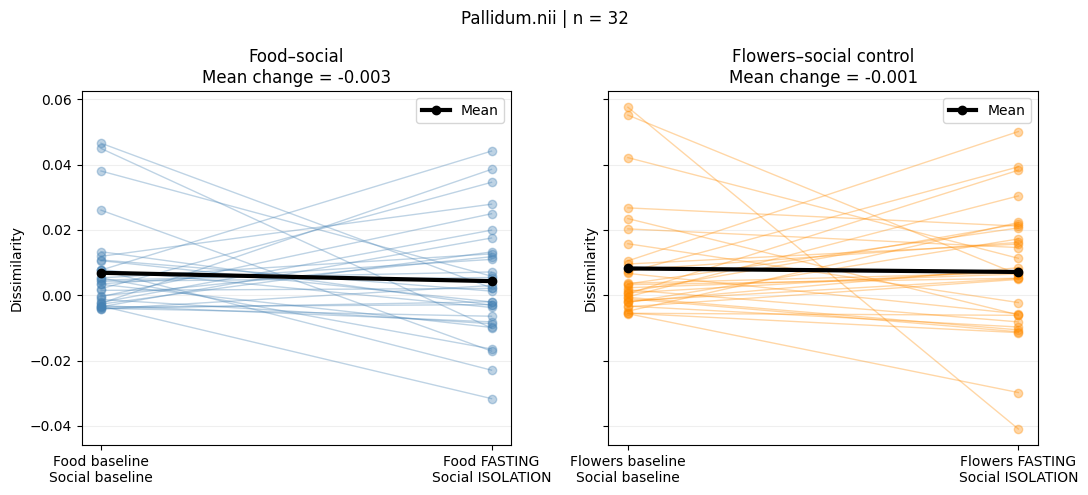

Skipping Brain-Stem.nii: insufficient complete pairs.


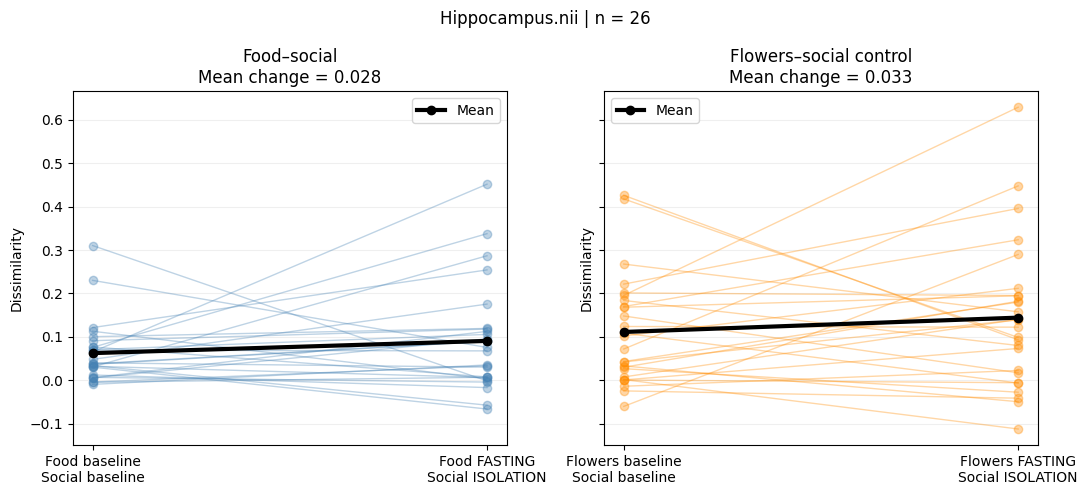

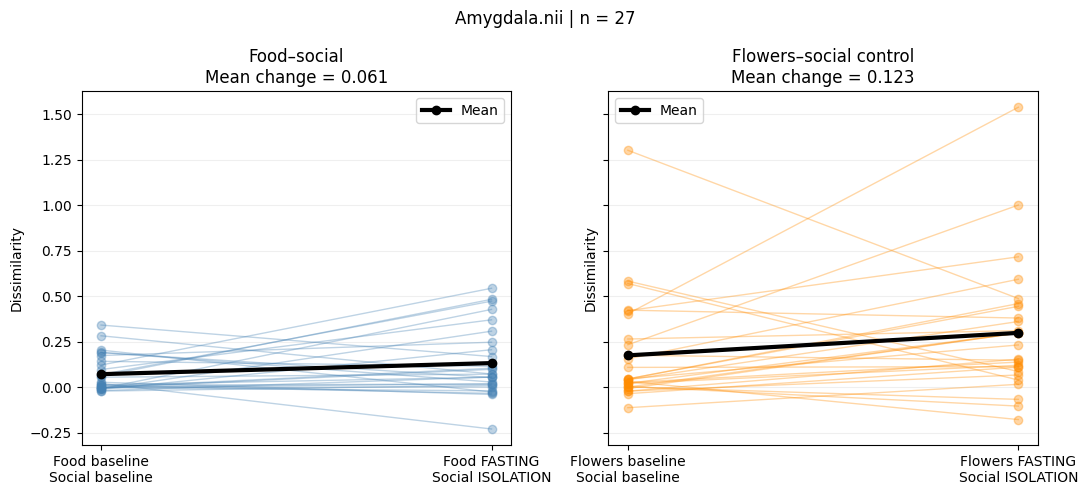

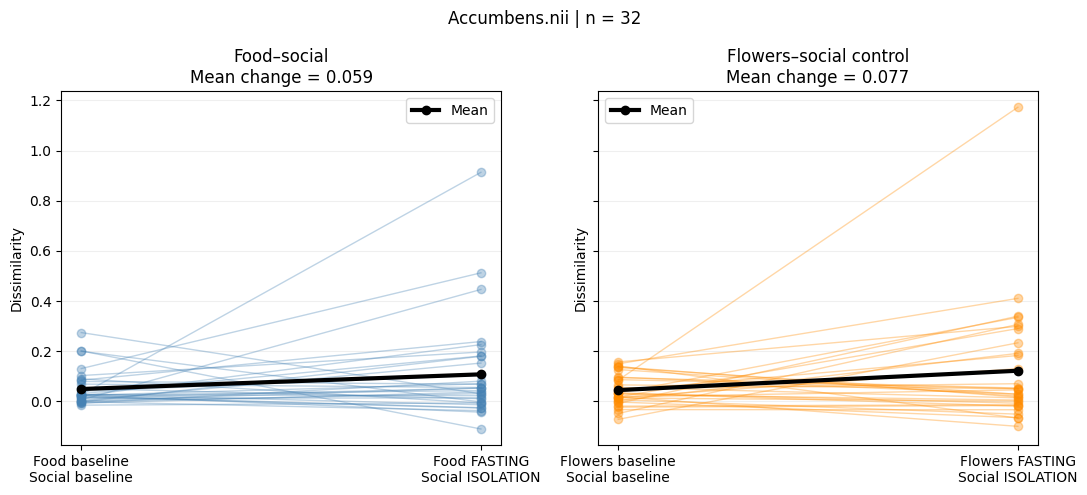

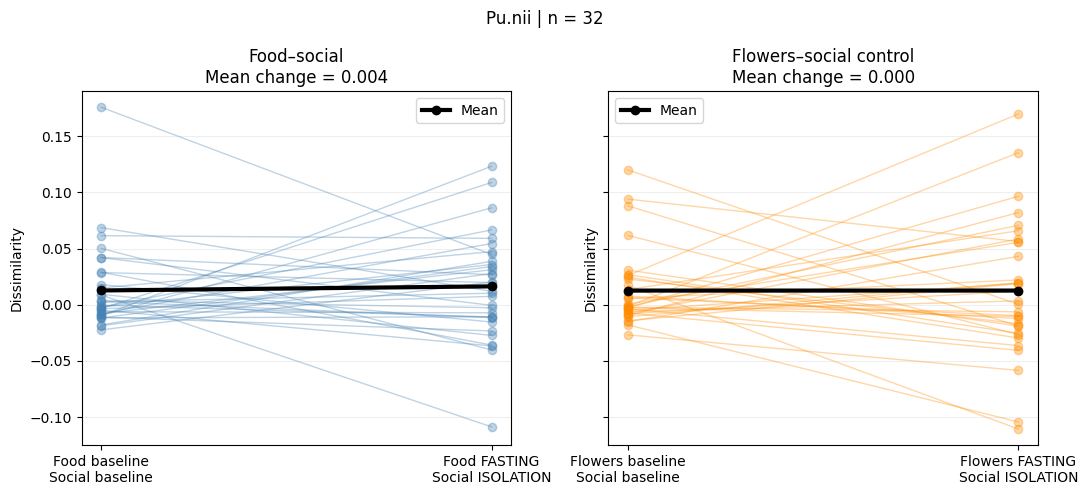

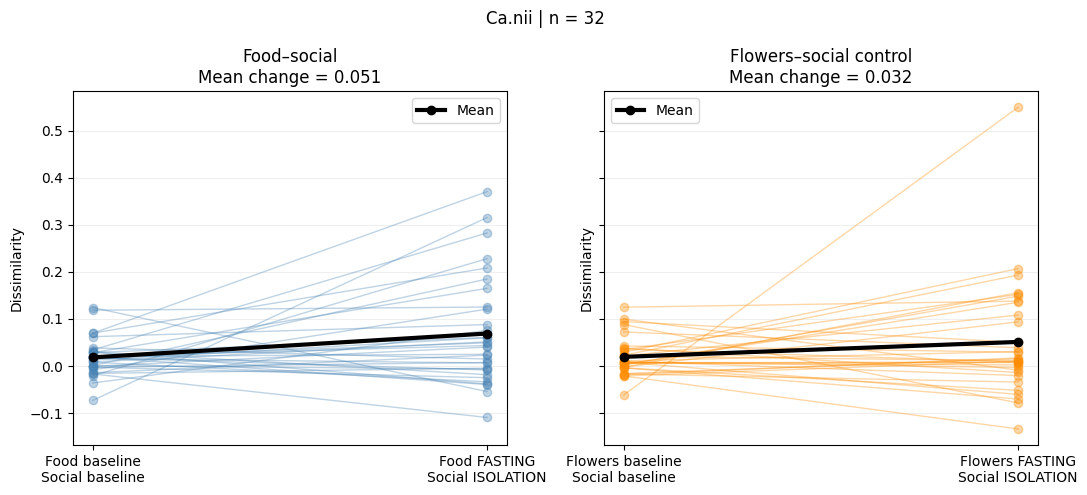

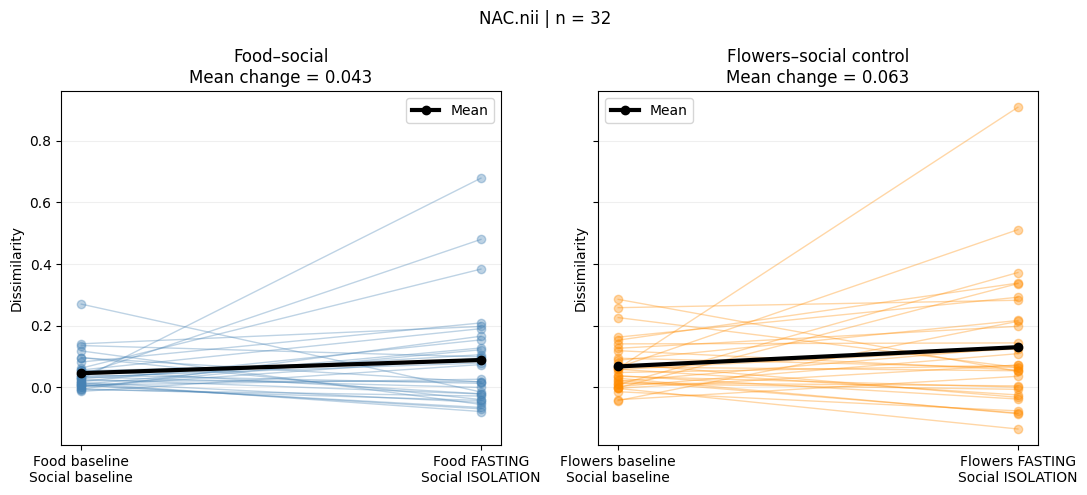

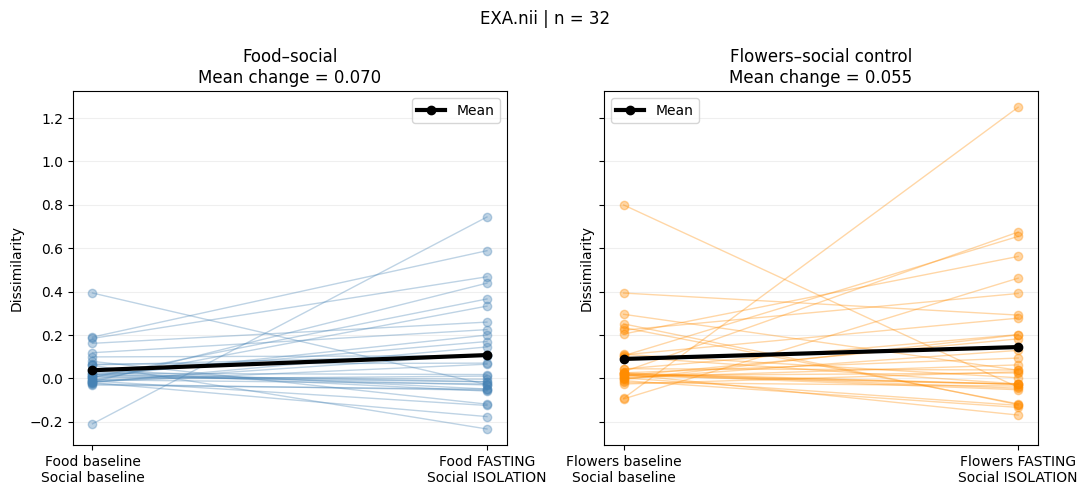

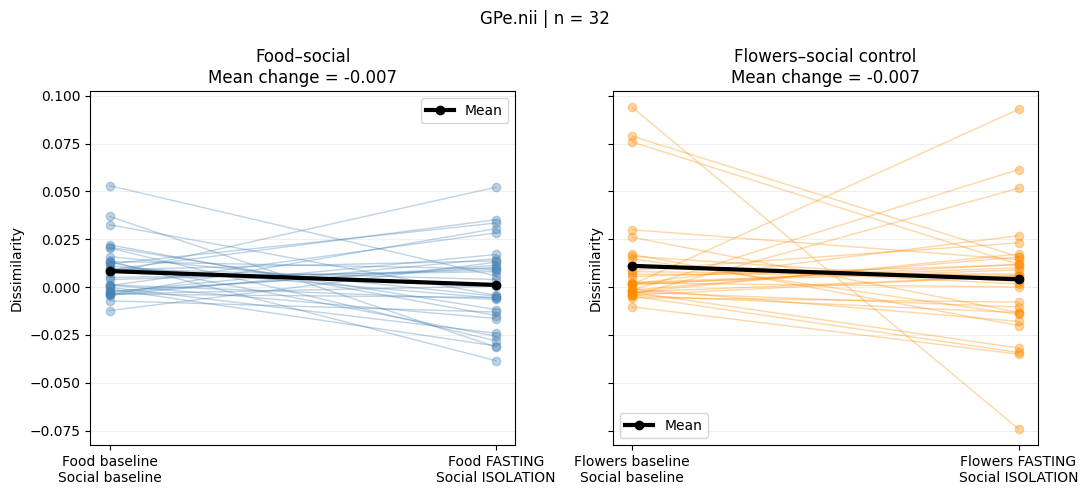

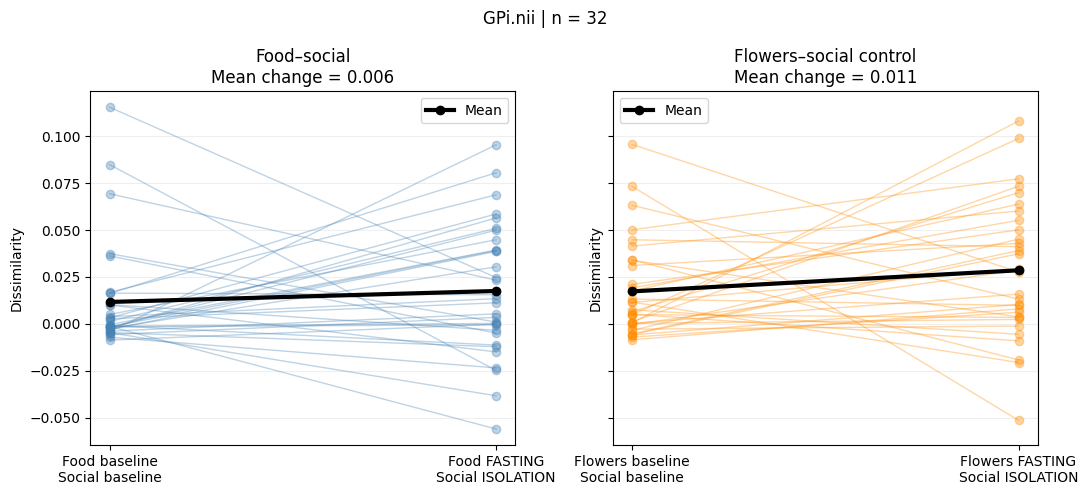

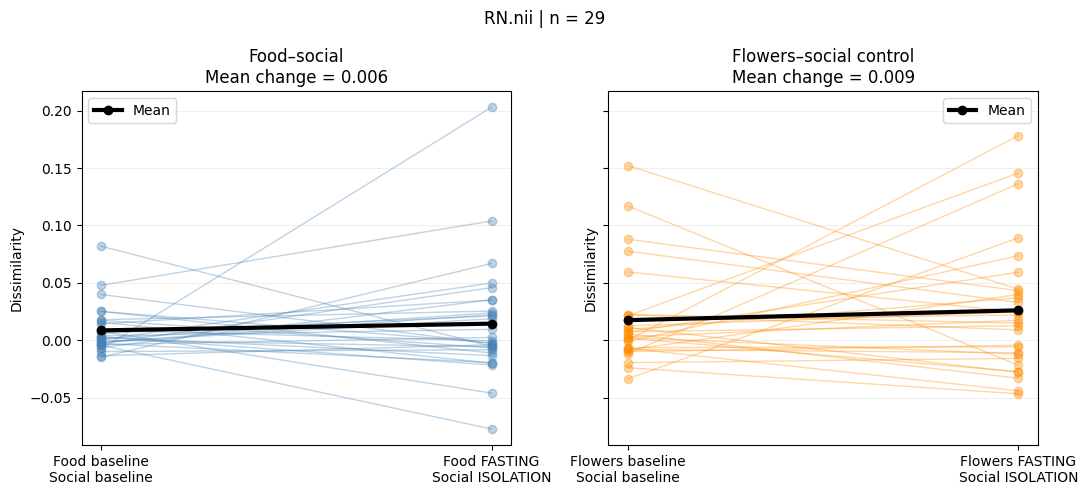

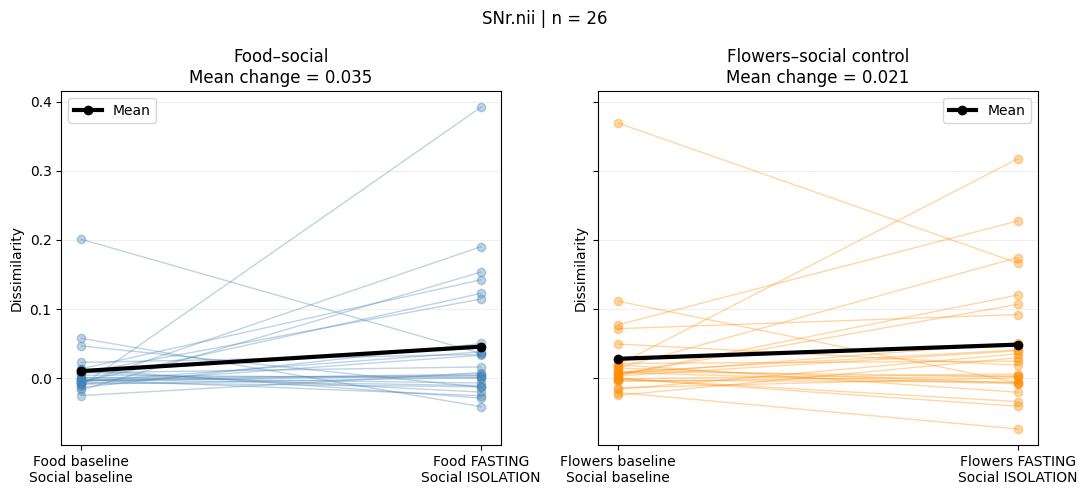

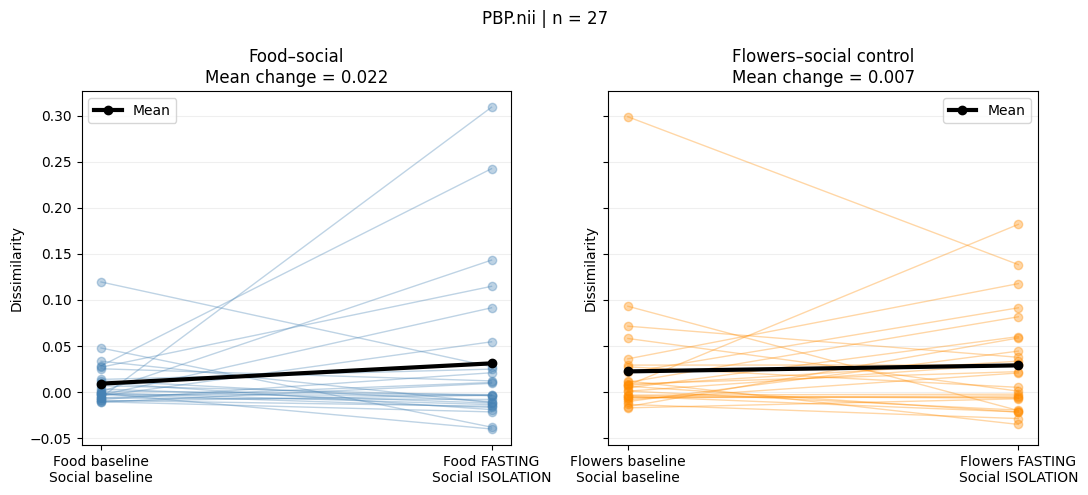

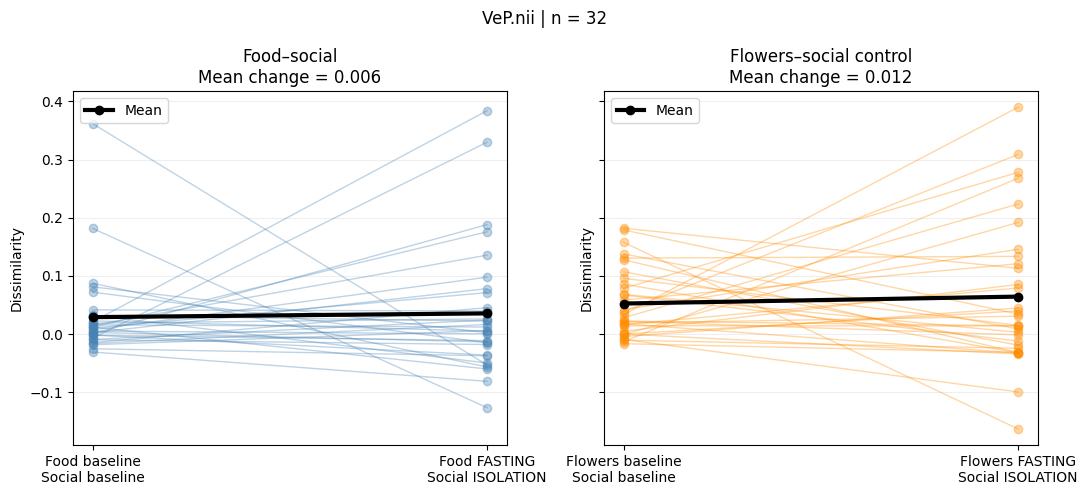

Skipping HN.nii: insufficient complete pairs.


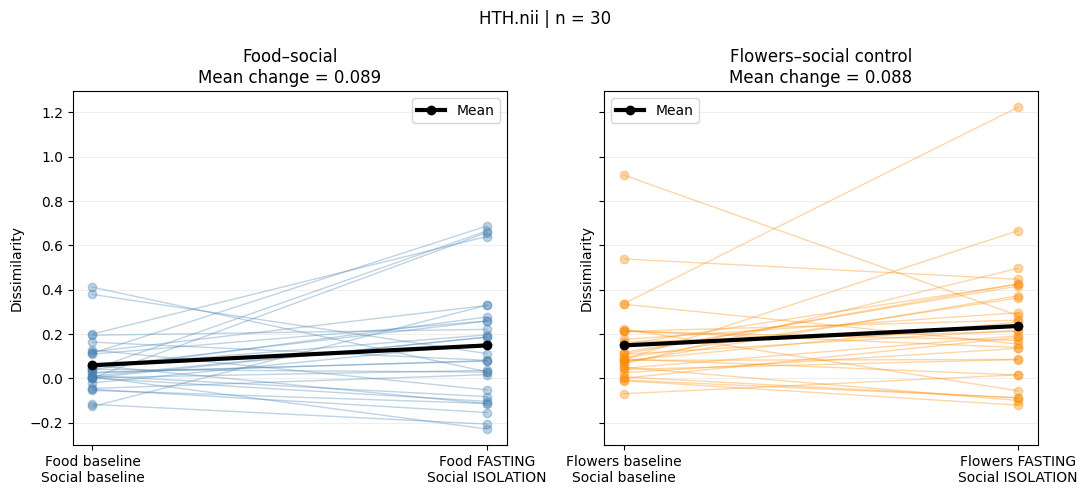

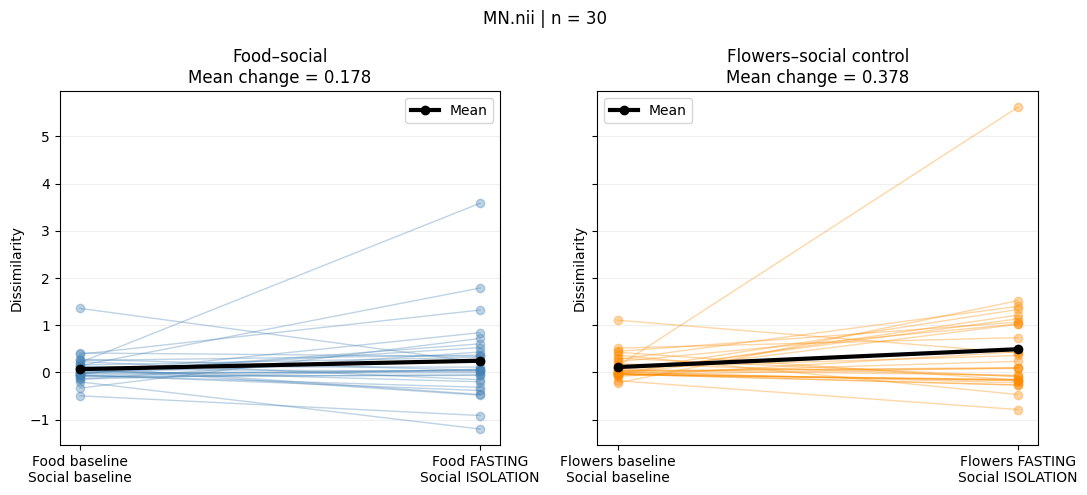

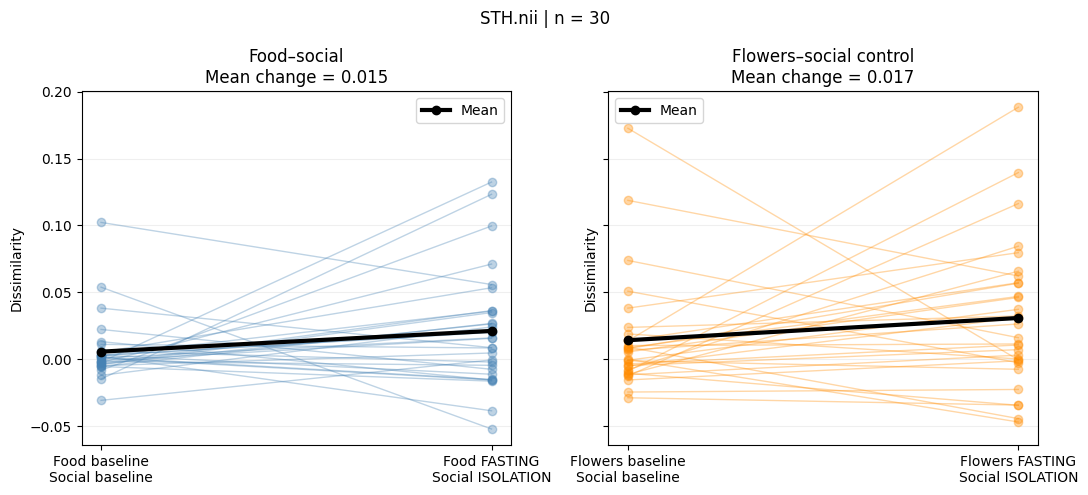

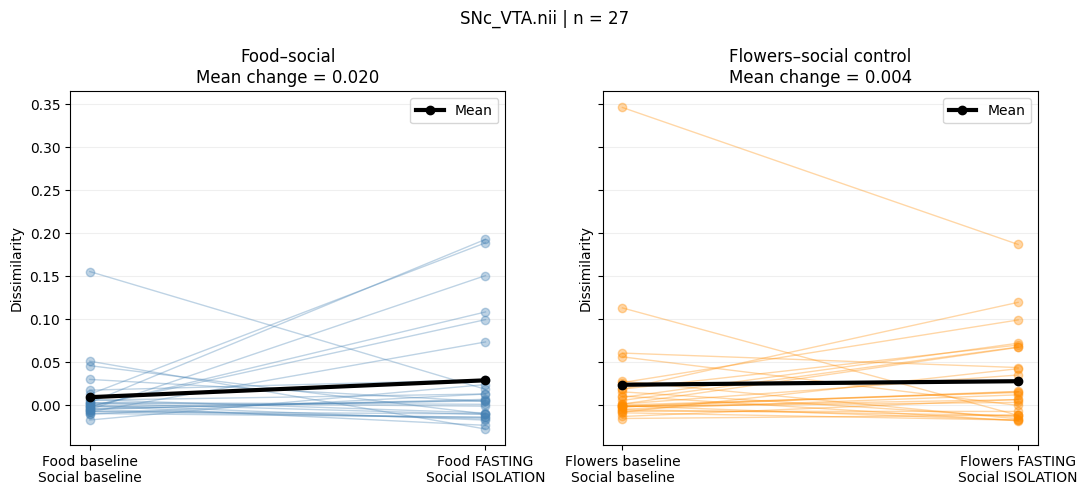

                                                                    ROI  n  food_change  control_change  difference_in_changes    p_food  p_change_difference  p_food_fdr  p_change_difference_fdr
                                                     Insular Cortex.nii 32      0.01063          0.0222               -0.01157    0.8104               0.7442       0.841                   0.9706
                                             Superior Frontal Gyrus.nii 28       0.6434          0.3673                 0.2761 0.0002071              0.04143    0.003796                   0.5696
                                               Middle Frontal Gyrus.nii 31        0.627          0.4651                 0.1619  0.002109               0.1916      0.0145                   0.9579
                          Inferior Frontal Gyrus, pars triangularis.nii  5     -0.09233         0.03035                -0.1227    0.7978                0.744       0.841                   0.9706
                         

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

conds = [str(c) for c in rdms["conditions"]]

def find_condition(cue, state):
    matches = [
        i for i, label in enumerate(conds)
        if {cue, state}.issubset(label.lower().split("_"))
    ]
    if len(matches) != 1:
        raise ValueError(
            f"Expected one condition for {cue} + {state}. "
            f"Available labels: {conds}"
        )
    print(f"{cue}, {state}: {conds[matches[0]]}")
    return matches[0]

food_base = find_condition("food", "baseline")
food_fast = find_condition("food", "fasting")
social_base = find_condition("social", "baseline")
social_iso = find_condition("social", "isolation")
flowers_base = find_condition("flowers", "baseline")
flowers_fast = find_condition("flowers", "fasting")

results = []

for roi_idx, roi_name in enumerate(rdms["rois"]):
    values = []

    for subj_idx in range(len(rdms["subjects"])):
        rdm = rdms["rdms"][subj_idx, roi_idx]

        values.append([
            rdm[food_base, social_base],
            rdm[food_fast, social_iso],       # Cross-condition target
            rdm[flowers_base, social_base],
            rdm[flowers_fast, social_iso],    # Cross-condition control
        ])

    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values).all(axis=1)]

    if len(values) < 2:
        print(f"Skipping {roi_name}: insufficient complete pairs.")
        continue

    food_baseline, food_matched, control_baseline, control_matched = values.T

    food_change = food_matched - food_baseline
    control_change = control_matched - control_baseline

    # Does the food–social change differ from the flowers–social change?
    interaction = ttest_rel(food_change, control_change)

    results.append({
        "ROI": str(roi_name),
        "n": len(values),
        "food_change": food_change.mean(),
        "control_change": control_change.mean(),
        "difference_in_changes": (food_change - control_change).mean(),
        "p_food": ttest_rel(food_matched, food_baseline).pvalue,
        "p_change_difference": interaction.pvalue,
    })

    fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

    panels = [
        (
            food_baseline, food_matched, "Food–social",
            ["Food baseline\nSocial baseline",
             "Food FASTING\nSocial ISOLATION"],
            "steelblue",
        ),
        (
            control_baseline, control_matched, "Flowers–social control",
            ["Flowers baseline\nSocial baseline",
             "Flowers FASTING\nSocial ISOLATION"],
            "darkorange",
        ),
    ]

    for ax, (baseline, matched, title, labels, color) in zip(axes, panels):
        for b, m in zip(baseline, matched):
            ax.plot(
                [0, 1], [b, m],
                "o-", color=color, alpha=0.35, linewidth=1,
            )

        ax.plot(
            [0, 1], [baseline.mean(), matched.mean()],
            "o-", color="black", linewidth=3, label="Mean",
        )

        ax.set_xticks([0, 1], labels)
        ax.set_title(
            f"{title}\nMean change = {(matched - baseline).mean():.3f}"
        )
        ax.set_ylabel("Dissimilarity")
        ax.grid(axis="y", alpha=0.2)
        ax.legend()

    fig.suptitle(f"{roi_name} | n = {len(values)}")
    plt.tight_layout()
    plt.show()

results_df = pd.DataFrame(results)

# Correct each family of tests across ROIs
if not results_df.empty:
    for column in ["p_food", "p_change_difference"]:
        results_df[column + "_fdr"] = np.nan
        valid = np.isfinite(results_df[column])

        if valid.any():
            results_df.loc[valid, column + "_fdr"] = multipletests(
                results_df.loc[valid, column],
                method="fdr_bh",
            )[1]

    print(results_df.to_string(index=False, float_format=lambda x: f"{x:.4g}"))